# Final Article-Ready Notebook v3  
# Adaptive Hard-Constrained DeepXDE-PINN for Nonlinear Viscoelastic Flow and Relaxation-Time Identification

This is **Version 2** of the Kaggle notebook. It improves the first run in four important ways:

1. **Hard boundary/initial constraints** are used through an output transform.  
2. **Relaxation time is bounded and positive** using a sigmoid transform.  
3. **Observation points are sampled from the informative interior domain** instead of randomly mixing in weak initial/boundary points.  
4. **Research-quality result handling** is added: sparse/noise repeats, mean/std tables, quality flags, and article-ready exports.

Recommended Kaggle settings: **GPU on, Internet on**.

**v3 final-run improvements:** rainbow contour figures, automatic display of all tables and figures, stronger final-mode settings, study RAR cycles, and larger inverse-observation settings.

## 1. Install DeepXDE

In [1]:
!pip -q install deepxde==1.15.0 scipy pandas matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 195.4/195.4 kB 7.7 MB/s eta 0:00:00


## 2. Backend and Imports

In [2]:
import os
os.environ["DDE_BACKEND"] = "pytorch"
os.environ["PYTHONHASHSEED"] = "1234"

import time
import math
import random
import warnings
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import deepxde as dde

warnings.filterwarnings("ignore")

print("DeepXDE version:", dde.__version__)
print("DeepXDE backend:", dde.backend.backend_name)

try:
    import torch
    print("PyTorch version:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())
    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))
except Exception as e:
    print("Torch check failed:", e)

from IPython.display import display, Image, Markdown

Using backend: pytorch
Other supported backends: tensorflow.compat.v1, tensorflow, jax, paddle.
paddle supports more examples now and is recommended.


DeepXDE version: 1.15.0
DeepXDE backend: pytorch
PyTorch version: 2.10.0+cu128
CUDA available: True
GPU: Tesla T4


## 3. Run Mode and Global Configuration

In [3]:
# ---------------------------------------------------------
# Choose mode:
# "quick"    = fast smoke test
# "balanced" = medium runtime
# "final"    = recommended final Kaggle run for article tables/figures
# "article"  = maximum quality, slowest
# ---------------------------------------------------------
RUN_MODE = "final"   # change to "quick" for testing, then "final" for article output

SEED = 1234
np.random.seed(SEED)
random.seed(SEED)
dde.config.set_random_seed(SEED)

dde.config.set_default_float("float32")
DTYPE = np.float32

if RUN_MODE == "quick":
    ADAM_ITERS_FORWARD = 3000
    ADAM_ITERS_INVERSE = 5000
    ADAM_ITERS_STUDY = 3000
    ADAM_ITERS_RAR = 2000
    USE_LBFGS_MAIN = False
    USE_LBFGS_STUDIES = False
    NUM_DOMAIN = 2500
    NUM_BOUNDARY = 0
    NUM_INITIAL = 0
    NUM_TEST = 5000
    RAR_CYCLES = 2
    RAR_CANDIDATES = 20000
    RAR_ADD_POINTS = 200
    STUDY_RAR_CYCLES = 0
    STUDY_REPEATS = 1
    SPARSE_SIZES = [50, 150, 300]
    NOISE_LEVELS = [0.00, 0.01, 0.03]
    LAMBDA_SWEEP_VALUES = [0.25, 0.50]

elif RUN_MODE == "balanced":
    ADAM_ITERS_FORWARD = 8000
    ADAM_ITERS_INVERSE = 12000
    ADAM_ITERS_STUDY = 7000
    ADAM_ITERS_RAR = 4000
    USE_LBFGS_MAIN = False
    USE_LBFGS_STUDIES = False
    NUM_DOMAIN = 6000
    NUM_BOUNDARY = 0
    NUM_INITIAL = 0
    NUM_TEST = 12000
    RAR_CYCLES = 3
    RAR_CANDIDATES = 50000
    RAR_ADD_POINTS = 400
    STUDY_RAR_CYCLES = 0
    STUDY_REPEATS = 1
    SPARSE_SIZES = [50, 150, 300, 600]
    NOISE_LEVELS = [0.00, 0.01, 0.03, 0.05]
    LAMBDA_SWEEP_VALUES = [0.25, 0.50, 0.75]

elif RUN_MODE == "final":
    # Recommended for final Kaggle run:
    # strong enough for article-quality tables, but not as slow as full article mode.
    ADAM_ITERS_FORWARD = 12000
    ADAM_ITERS_INVERSE = 22000
    ADAM_ITERS_STUDY = 10000
    ADAM_ITERS_RAR = 6000
    USE_LBFGS_MAIN = True
    USE_LBFGS_STUDIES = False
    NUM_DOMAIN = 9000
    NUM_BOUNDARY = 0
    NUM_INITIAL = 0
    NUM_TEST = 25000
    RAR_CYCLES = 4
    RAR_CANDIDATES = 80000
    RAR_ADD_POINTS = 600
    STUDY_RAR_CYCLES = 1
    STUDY_REPEATS = 2
    SPARSE_SIZES = [50, 100, 200, 500, 1000]
    NOISE_LEVELS = [0.00, 0.01, 0.03, 0.05, 0.10]
    LAMBDA_SWEEP_VALUES = [0.20, 0.35, 0.50, 0.75, 1.00]

elif RUN_MODE == "article":
    ADAM_ITERS_FORWARD = 20000
    ADAM_ITERS_INVERSE = 30000
    ADAM_ITERS_STUDY = 15000
    ADAM_ITERS_RAR = 8000
    USE_LBFGS_MAIN = True
    USE_LBFGS_STUDIES = False
    NUM_DOMAIN = 12000
    NUM_BOUNDARY = 0
    NUM_INITIAL = 0
    NUM_TEST = 30000
    RAR_CYCLES = 5
    RAR_CANDIDATES = 100000
    RAR_ADD_POINTS = 700
    STUDY_RAR_CYCLES = 1
    STUDY_REPEATS = 3
    SPARSE_SIZES = [25, 50, 100, 200, 500, 1000]
    NOISE_LEVELS = [0.00, 0.01, 0.03, 0.05, 0.10]
    LAMBDA_SWEEP_VALUES = [0.20, 0.35, 0.50, 0.75, 1.00]
else:
    raise ValueError("RUN_MODE must be 'quick', 'balanced', 'final', or 'article'.")

RUN_FORWARD_PINN = True
RUN_INVERSE_PINN = True
RUN_SPARSE_STUDY = True
RUN_NOISE_STUDY = True
RUN_RAR_ADAPTIVE = True
RUN_LAMBDA_SWEEP = True

USE_HARD_CONSTRAINTS = True
USE_BOUNDED_LAMBDA = True

# Loss weights. Data weights help inverse lambda recovery from sparse/noisy measurements.
DATA_WEIGHT_U = 25.0
DATA_WEIGHT_SIGMA = 25.0
PDE_WEIGHT_MOMENTUM = 1.0
PDE_WEIGHT_CONSTITUTIVE = 1.0

# Final article figure settings
PLOT_CMAP = "rainbow"       # user-preferred rainbow contours
CONTOUR_LEVELS = 90
DISPLAY_TABLES_WHEN_SAVED = True
DISPLAY_ALL_OUTPUTS_AT_END = True
MAX_TABLE_ROWS_TO_DISPLAY = 30

OUTDIR = Path("viscoelastic_pinn_outputs_v3_final")
FIGDIR = OUTDIR / "figures"
TABLEDIR = OUTDIR / "tables"
MODELDIR = OUTDIR / "models"

for d in [OUTDIR, FIGDIR, TABLEDIR, MODELDIR]:
    d.mkdir(parents=True, exist_ok=True)

print("RUN_MODE:", RUN_MODE)
print("USE_HARD_CONSTRAINTS:", USE_HARD_CONSTRAINTS)
print("USE_BOUNDED_LAMBDA:", USE_BOUNDED_LAMBDA)
print("PLOT_CMAP:", PLOT_CMAP)
print("STUDY_REPEATS:", STUDY_REPEATS)
print("STUDY_RAR_CYCLES:", STUDY_RAR_CYCLES)
print("Output folder:", OUTDIR.resolve())

Set the default float type to float32
RUN_MODE: final
USE_HARD_CONSTRAINTS: True
USE_BOUNDED_LAMBDA: True
PLOT_CMAP: rainbow
STUDY_REPEATS: 2
STUDY_RAR_CYCLES: 1
Output folder: /kaggle/working/viscoelastic_pinn_outputs_v3_final


## 4. Mathematical Model

We solve a nonlinear stabilized viscoelastic PDE:

\[
u_t - D u_{xx} - \frac{1}{\rho}\sigma_x = 0
\]

\[
\lambda \sigma_t + \sigma - \eta u_x - \alpha u^2 = 0
\]

The unknown relaxation time \(\lambda\) is identified from sparse/noisy observations.

Hard constraints are applied using:

\[
u(x,t) = (1-t)\sin(\pi x) + t x(1-x)N_u(x,t)
\]

\[
\sigma(x,t) = (1-t)\sigma_0(x) + tN_\sigma(x,t)
\]

In [4]:
PARAMS = {
    "rho": 1.0,
    "D": 0.005,
    "eta": 0.05,
    "alpha": 0.10,
    "lambda_true": 0.50,
    "L": 1.0,
    "T": 1.0,
    "lambda_min": 0.05,
    "lambda_max": 2.00,
}

params_df = pd.DataFrame([{"Symbol": k, "Value": v} for k, v in PARAMS.items()])
params_df.to_csv(TABLEDIR / "table_01_physical_parameters.csv", index=False)
params_df

,Symbol,Value
0,rho,1.000
1,D,0.005
2,eta,0.050
3,alpha,0.100
4,lambda_true,0.500
5,L,1.000
6,T,1.000
7,lambda_min,0.050
8,lambda_max,2.000


## 5. Finite-Difference Reference Solver

In [5]:
def generate_reference_solution(
    lambda_true=0.5,
    rho=1.0,
    D=0.005,
    eta=0.05,
    alpha=0.10,
    L=1.0,
    T=1.0,
    Nx=121,
    Nt=1401,
    **unused,
):
    # Explicit FDM reference solution for the nonlinear viscoelastic PDE.
    x = np.linspace(0.0, L, Nx)
    t = np.linspace(0.0, T, Nt)
    dx = x[1] - x[0]
    dt = t[1] - t[0]

    diffusion_cfl = D * dt / dx**2
    print(f"dx={dx:.4e}, dt={dt:.4e}, diffusion CFL={diffusion_cfl:.4e}")

    if diffusion_cfl > 0.45:
        print("Warning: diffusion CFL is high for explicit FDM.")

    U = np.zeros((Nt, Nx), dtype=np.float64)
    S = np.zeros((Nt, Nx), dtype=np.float64)

    U[0, :] = np.sin(np.pi * x)
    U[0, 0] = 0.0
    U[0, -1] = 0.0

    Ux0 = np.gradient(U[0, :], dx, edge_order=2)
    S[0, :] = eta * Ux0 + alpha * U[0, :] ** 2

    for n in range(Nt - 1):
        Uxx = (U[n, 2:] - 2.0 * U[n, 1:-1] + U[n, :-2]) / dx**2
        Sx = (S[n, 2:] - S[n, :-2]) / (2.0 * dx)

        U[n + 1, 1:-1] = U[n, 1:-1] + dt * (D * Uxx + Sx / rho)
        U[n + 1, 0] = 0.0
        U[n + 1, -1] = 0.0

        Ux = np.gradient(U[n, :], dx, edge_order=2)
        S[n + 1, :] = S[n, :] + dt * ((eta * Ux + alpha * U[n, :] ** 2 - S[n, :]) / lambda_true)

        if not np.all(np.isfinite(U[n + 1, :])) or not np.all(np.isfinite(S[n + 1, :])):
            raise FloatingPointError(f"Reference solver became unstable at step {n}")

    return {
        "x": x,
        "t": t,
        "U": U,
        "S": S,
        "lambda_true": lambda_true,
        "rho": rho,
        "D": D,
        "eta": eta,
        "alpha": alpha,
    }


def reference_to_dataframe(ref):
    X_mesh, T_mesh = np.meshgrid(ref["x"], ref["t"])
    return pd.DataFrame({
        "x": X_mesh.ravel(),
        "t": T_mesh.ravel(),
        "u": ref["U"].ravel(),
        "sigma": ref["S"].ravel(),
    })


ref = generate_reference_solution(**PARAMS)
ref_df = reference_to_dataframe(ref)
ref_df.to_csv(OUTDIR / "reference_viscoelastic_solution.csv", index=False)
print("Reference data shape:", ref_df.shape)
ref_df.head()

dx=8.3333e-03, dt=7.1429e-04, diffusion CFL=5.1429e-02
Reference data shape: (169521, 4)


,x,t,u,sigma
0,0.000000,0.0,0.000000,0.157116
1,0.008333,0.0,0.026177,0.157076
2,0.016667,0.0,0.052336,0.157120
3,0.025000,0.0,0.078459,0.157193
4,0.033333,0.0,0.104528,0.157294


## 6. Plotting, Metrics, and Table Helpers

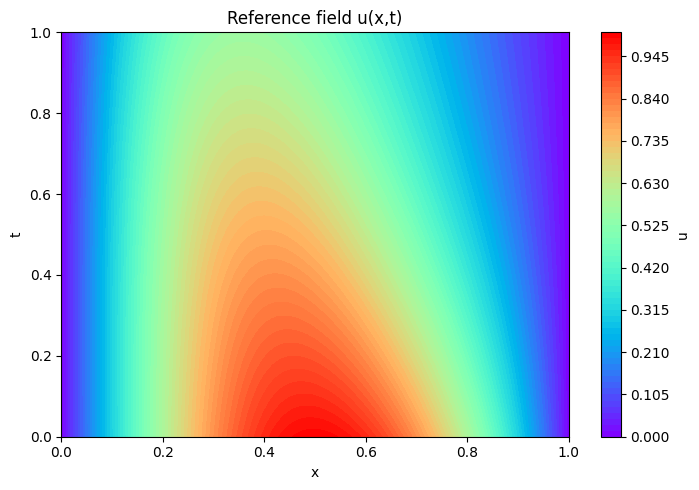

Saved: viscoelastic_pinn_outputs_v3_final/figures/fig_01_reference_u.png


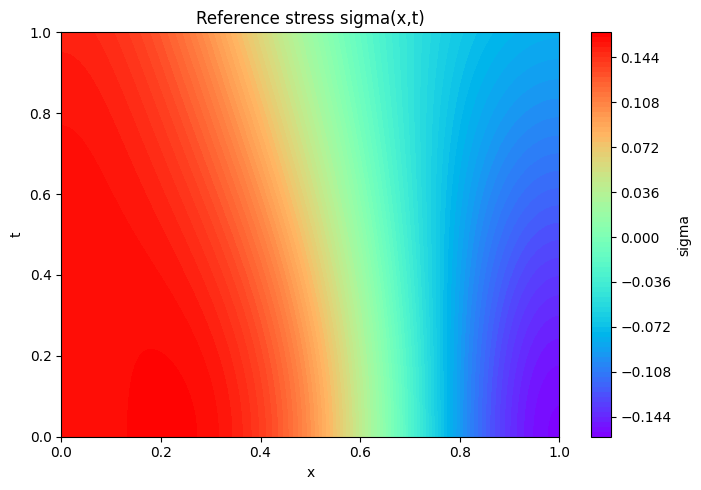

Saved: viscoelastic_pinn_outputs_v3_final/figures/fig_02_reference_sigma.png


In [6]:
def save_table(df, filename, display_now=None, max_rows=None):
    """Save a table as CSV and optionally display it in the notebook output."""
    path = TABLEDIR / filename
    df.to_csv(path, index=False)
    print("Saved:", path)

    if display_now is None:
        display_now = DISPLAY_TABLES_WHEN_SAVED
    if max_rows is None:
        max_rows = MAX_TABLE_ROWS_TO_DISPLAY

    if display_now:
        display(Markdown(f"### {filename}"))
        if len(df) > max_rows:
            display(df.head(max_rows))
            print(f"Displayed first {max_rows} of {len(df)} rows.")
        else:
            display(df)
    return path


def make_xt_grid(ref):
    X_mesh, T_mesh = np.meshgrid(ref["x"], ref["t"])
    X_eval = np.column_stack([X_mesh.ravel(), T_mesh.ravel()]).astype(DTYPE)
    return X_mesh, T_mesh, X_eval


def l2_relative_error(y_true, y_pred, eps=1e-12):
    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)
    return np.linalg.norm(y_true - y_pred) / (np.linalg.norm(y_true) + eps)


def max_abs_error(y_true, y_pred):
    return np.max(np.abs(np.asarray(y_true) - np.asarray(y_pred)))


def plot_field(x, t, Z, title, filename, label, cmap=None, levels=None):
    """Article-style rainbow contour field plot."""
    cmap = PLOT_CMAP if cmap is None else cmap
    levels = CONTOUR_LEVELS if levels is None else levels

    X_mesh, T_mesh = np.meshgrid(x, t)

    plt.figure(figsize=(7.2, 5.0))
    contour = plt.contourf(X_mesh, T_mesh, Z, levels=levels, cmap=cmap)
    plt.colorbar(contour, label=label)
    plt.xlabel("x")
    plt.ylabel("t")
    plt.title(title)
    plt.tight_layout()

    path = FIGDIR / filename
    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()
    print("Saved:", path)


def plot_curve(x, y, title, xlabel, ylabel, filename):
    plt.figure(figsize=(6.8, 4.8))
    plt.plot(x, y, marker="o", linewidth=2)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    path = FIGDIR / filename
    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()
    print("Saved:", path)


def plot_errorbar(df, xcol, ycol, yerrcol, title, xlabel, ylabel, filename):
    plt.figure(figsize=(6.8, 4.8))

    yerr = None
    if yerrcol in df.columns and not df[yerrcol].isna().all():
        yerr = df[yerrcol]

    plt.errorbar(df[xcol], df[ycol], yerr=yerr, marker="o", linewidth=2, capsize=4)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    path = FIGDIR / filename
    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()
    print("Saved:", path)


plot_field(ref["x"], ref["t"], ref["U"], "Reference field u(x,t)", "fig_01_reference_u.png", "u")
plot_field(ref["x"], ref["t"], ref["S"], "Reference stress sigma(x,t)", "fig_02_reference_sigma.png", "sigma")

## 7. Lambda Parameter Handling

In [7]:
def inverse_sigmoid_numpy(y):
    y = np.clip(y, 1e-6, 1.0 - 1e-6)
    return np.log(y / (1.0 - y))


def make_bounded_lambda_spec(lambda_init, lower=None, upper=None):
    lower = PARAMS["lambda_min"] if lower is None else lower
    upper = PARAMS["lambda_max"] if upper is None else upper
    y = (lambda_init - lower) / (upper - lower)
    raw_init = float(inverse_sigmoid_numpy(y))
    raw = dde.Variable(raw_init)
    return {"type": "bounded_lambda", "raw": raw, "lower": lower, "upper": upper}


def lambda_from_spec_for_pde(lambda_spec):
    if isinstance(lambda_spec, dict) and lambda_spec.get("type") == "bounded_lambda":
        raw = lambda_spec["raw"]
        lower = lambda_spec["lower"]
        upper = lambda_spec["upper"]

        if dde.backend.backend_name == "pytorch":
            import torch
            return lower + (upper - lower) * torch.sigmoid(raw)

        return lower + (upper - lower) * dde.backend.sigmoid(raw)

    return lambda_spec


def variable_to_float(var):
    try:
        return float(dde.backend.to_numpy(var))
    except Exception:
        pass
    try:
        return float(var.detach().cpu().numpy())
    except Exception:
        pass
    try:
        return float(var.value().numpy())
    except Exception:
        pass
    try:
        return float(var)
    except Exception as exc:
        print("Could not convert variable:", exc)
        return np.nan


def lambda_spec_to_float(lambda_spec):
    if isinstance(lambda_spec, dict) and lambda_spec.get("type") == "bounded_lambda":
        raw_float = variable_to_float(lambda_spec["raw"])
        lower = lambda_spec["lower"]
        upper = lambda_spec["upper"]
        sigmoid = 1.0 / (1.0 + math.exp(-raw_float))
        return lower + (upper - lower) * sigmoid
    return float(lambda_spec)


def lambda_external_variables(lambda_spec):
    if isinstance(lambda_spec, dict) and lambda_spec.get("type") == "bounded_lambda":
        return [lambda_spec["raw"]]
    return None


def transform_raw_history_to_lambda(raw_values, lower=None, upper=None):
    lower = PARAMS["lambda_min"] if lower is None else lower
    upper = PARAMS["lambda_max"] if upper is None else upper
    raw_values = np.asarray(raw_values, dtype=float)
    return lower + (upper - lower) / (1.0 + np.exp(-raw_values))

## 8. DeepXDE PDE, Geometry, Hard Constraints, and Problem Builder

In [8]:
geom = dde.geometry.Interval(0.0, PARAMS["L"])
timedomain = dde.geometry.TimeDomain(0.0, PARAMS["T"])
geomtime = dde.geometry.GeometryXTime(geom, timedomain)


def initial_u_numpy(X):
    x = X[:, 0:1]
    return np.sin(np.pi * x)


def initial_sigma_numpy(X):
    x = X[:, 0:1]
    u0 = np.sin(np.pi * x)
    ux0 = np.pi * np.cos(np.pi * x)
    return PARAMS["eta"] * ux0 + PARAMS["alpha"] * u0**2


def zero_bc(X):
    return np.zeros((len(X), 1), dtype=DTYPE)


def on_boundary(X, on_boundary):
    return on_boundary


def on_initial(X, on_initial):
    return on_initial


def output_transform_pytorch(x, y):
    import torch

    xs = x[:, 0:1]
    ts = x[:, 1:2]

    pi_t = torch.tensor(np.pi, dtype=xs.dtype, device=xs.device)
    u0 = torch.sin(pi_t * xs)
    ux0 = pi_t * torch.cos(pi_t * xs)
    sigma0 = PARAMS["eta"] * ux0 + PARAMS["alpha"] * u0**2

    u = (1.0 - ts) * u0 + ts * xs * (1.0 - xs) * y[:, 0:1]
    sigma = (1.0 - ts) * sigma0 + ts * y[:, 1:2]

    return torch.cat([u, sigma], dim=1)


def make_pde(lambda_spec, params):
    rho = params["rho"]
    D = params["D"]
    eta = params["eta"]
    alpha = params["alpha"]

    def pde(x, y):
        u = y[:, 0:1]
        sigma = y[:, 1:2]

        u_t = dde.grad.jacobian(y, x, i=0, j=1)
        u_x = dde.grad.jacobian(y, x, i=0, j=0)
        u_xx = dde.grad.hessian(y, x, component=0, i=0, j=0)

        sigma_t = dde.grad.jacobian(y, x, i=1, j=1)
        sigma_x = dde.grad.jacobian(y, x, i=1, j=0)

        lam = lambda_from_spec_for_pde(lambda_spec)

        r_momentum = u_t - D * u_xx - sigma_x / rho
        r_constitutive = lam * sigma_t + sigma - eta * u_x - alpha * u**2

        return [r_momentum, r_constitutive]

    return pde


def make_loss_weights(has_observations):
    if USE_HARD_CONSTRAINTS:
        weights = [PDE_WEIGHT_MOMENTUM, PDE_WEIGHT_CONSTITUTIVE]
        if has_observations:
            weights += [DATA_WEIGHT_U, DATA_WEIGHT_SIGMA]
        return weights

    weights = [PDE_WEIGHT_MOMENTUM, PDE_WEIGHT_CONSTITUTIVE, 10.0, 10.0, 10.0]
    if has_observations:
        weights += [DATA_WEIGHT_U, DATA_WEIGHT_SIGMA]
    return weights


def make_problem(lambda_spec, observations=None, num_domain=6000, num_boundary=0, num_initial=0, num_test=10000):
    pde = make_pde(lambda_spec, PARAMS)
    conditions = []

    if not USE_HARD_CONSTRAINTS:
        bc_u = dde.icbc.DirichletBC(geomtime, zero_bc, on_boundary, component=0)
        ic_u = dde.icbc.IC(geomtime, initial_u_numpy, on_initial, component=0)
        ic_sigma = dde.icbc.IC(geomtime, initial_sigma_numpy, on_initial, component=1)
        conditions.extend([bc_u, ic_u, ic_sigma])

    data_kwargs = {}
    if observations is not None:
        observe_u = dde.icbc.PointSetBC(observations["X"], observations["u"], component=0)
        observe_sigma = dde.icbc.PointSetBC(observations["X"], observations["sigma"], component=1)
        conditions.extend([observe_u, observe_sigma])
        data_kwargs["anchors"] = observations["X"]

    data = dde.data.TimePDE(
        geomtime,
        pde,
        conditions,
        num_domain=num_domain,
        num_boundary=num_boundary,
        num_initial=num_initial,
        num_test=num_test,
        **data_kwargs
    )

    loss_weights = make_loss_weights(has_observations=observations is not None)
    return data, pde, loss_weights


def make_network(width=80, depth=5):
    net = dde.nn.FNN([2] + [width] * depth + [2], "tanh", "Glorot normal")
    if USE_HARD_CONSTRAINTS:
        if dde.backend.backend_name != "pytorch":
            raise RuntimeError("This hard-constraint transform is written for PyTorch backend.")
        net.apply_output_transform(output_transform_pytorch)
    return net


hyperparams_df = pd.DataFrame([
    {"Item": "Network input", "Value": "(x,t)"},
    {"Item": "Network output", "Value": "(u,sigma)"},
    {"Item": "Hidden layers", "Value": 5},
    {"Item": "Neurons per hidden layer", "Value": 80},
    {"Item": "Activation", "Value": "tanh"},
    {"Item": "Initializer", "Value": "Glorot normal"},
    {"Item": "Hard constraints", "Value": str(USE_HARD_CONSTRAINTS)},
    {"Item": "Lambda parameterization", "Value": "bounded sigmoid raw variable"},
    {"Item": "Optimizer stage 1", "Value": "Adam"},
    {"Item": "Optimizer stage 2", "Value": "L-BFGS optional"},
    {"Item": "Backend", "Value": "PyTorch"},
])
save_table(hyperparams_df, "table_02_network_hyperparameters.csv")
hyperparams_df

Saved: viscoelastic_pinn_outputs_v3_final/tables/table_02_network_hyperparameters.csv


### table_02_network_hyperparameters.csv

,Item,Value
0,Network input,"(x,t)"
1,Network output,"(u,sigma)"
2,Hidden layers,5
3,Neurons per hidden layer,80
4,Activation,tanh
5,Initializer,Glorot normal
6,Hard constraints,True
7,Lambda parameterization,bounded sigmoid raw variable
8,Optimizer stage 1,Adam
9,Optimizer stage 2,L-BFGS optional


,Item,Value
0,Network input,"(x,t)"
1,Network output,"(u,sigma)"
2,Hidden layers,5
3,Neurons per hidden layer,80
4,Activation,tanh
5,Initializer,Glorot normal
6,Hard constraints,True
7,Lambda parameterization,bounded sigmoid raw variable
8,Optimizer stage 1,Adam
9,Optimizer stage 2,L-BFGS optional


## 9. Training, Evaluation, and Observation Sampling Helpers

In [9]:
def train_model(
    model,
    adam_iters,
    lr=1e-3,
    external_vars=None,
    callbacks=None,
    use_lbfgs=False,
    loss_weights=None,
    display_every=1000,
):
    callbacks = callbacks or []
    compile_kwargs = {}
    if external_vars is not None:
        compile_kwargs["external_trainable_variables"] = external_vars
    if loss_weights is not None:
        compile_kwargs["loss_weights"] = loss_weights

    t0 = time.time()
    model.compile("adam", lr=lr, **compile_kwargs)
    losshistory, train_state = model.train(
        iterations=adam_iters,
        callbacks=callbacks,
        display_every=display_every,
    )

    if use_lbfgs:
        try:
            model.compile("L-BFGS", **compile_kwargs)
            losshistory, train_state = model.train(callbacks=callbacks, display_every=display_every)
        except Exception as e1:
            print("L-BFGS failed, trying L-BFGS-B:", e1)
            try:
                model.compile("L-BFGS-B", **compile_kwargs)
                losshistory, train_state = model.train(callbacks=callbacks, display_every=display_every)
            except Exception as e2:
                print("Skipping L-BFGS. Reason:", e2)

    elapsed = time.time() - t0
    return losshistory, train_state, elapsed


def evaluate_model(model, ref, tag="model", save_figures=True):
    X_mesh, T_mesh, X_eval = make_xt_grid(ref)
    y_pred = model.predict(X_eval)

    U_pred = y_pred[:, 0].reshape(ref["U"].shape)
    S_pred = y_pred[:, 1].reshape(ref["S"].shape)
    U_true = ref["U"]
    S_true = ref["S"]

    metrics = {
        "tag": tag,
        "u_l2_relative_error": l2_relative_error(U_true, U_pred),
        "sigma_l2_relative_error": l2_relative_error(S_true, S_pred),
        "u_max_abs_error": max_abs_error(U_true, U_pred),
        "sigma_max_abs_error": max_abs_error(S_true, S_pred),
    }

    pred_df = pd.DataFrame({
        "x": X_eval[:, 0],
        "t": X_eval[:, 1],
        "u_true": U_true.ravel(),
        "sigma_true": S_true.ravel(),
        "u_pred": U_pred.ravel(),
        "sigma_pred": S_pred.ravel(),
        "u_error": (U_pred - U_true).ravel(),
        "sigma_error": (S_pred - S_true).ravel(),
    })
    pred_df.to_csv(OUTDIR / f"prediction_{tag}.csv", index=False)

    if save_figures:
        plot_field(ref["x"], ref["t"], U_pred, f"{tag}: predicted u(x,t)", f"fig_{tag}_predicted_u.png", "u_pred")
        plot_field(ref["x"], ref["t"], S_pred, f"{tag}: predicted sigma(x,t)", f"fig_{tag}_predicted_sigma.png", "sigma_pred")
        plot_field(ref["x"], ref["t"], np.abs(U_pred - U_true), f"{tag}: absolute error in u", f"fig_{tag}_error_u.png", "|error|")
        plot_field(ref["x"], ref["t"], np.abs(S_pred - S_true), f"{tag}: absolute error in sigma", f"fig_{tag}_error_sigma.png", "|error|")

    return metrics, pred_df


def sample_observations(ref, n_obs=200, noise_level=0.0, seed=1234, interior_only=True):
    rng = np.random.default_rng(seed)
    df = reference_to_dataframe(ref)

    if interior_only:
        df = df[
            (df["x"] > 0.05 * PARAMS["L"]) &
            (df["x"] < 0.95 * PARAMS["L"]) &
            (df["t"] > 0.05 * PARAMS["T"]) &
            (df["t"] < 0.98 * PARAMS["T"])
        ].copy()

    if n_obs > len(df):
        raise ValueError(f"n_obs={n_obs} is larger than sample pool {len(df)}.")

    idx = rng.choice(len(df), size=n_obs, replace=False)
    sampled = df.iloc[idx].copy()

    u = sampled["u"].to_numpy().reshape(-1, 1)
    sigma = sampled["sigma"].to_numpy().reshape(-1, 1)

    if noise_level > 0:
        u = u + noise_level * np.std(u) * rng.normal(size=u.shape)
        sigma = sigma + noise_level * np.std(sigma) * rng.normal(size=sigma.shape)

    X = sampled[["x", "t"]].to_numpy()

    return {
        "X": X.astype(DTYPE),
        "u": u.astype(DTYPE),
        "sigma": sigma.astype(DTYPE),
        "noise_level": noise_level,
        "n_obs": n_obs,
    }


def aggregate_results(df, group_cols):
    numeric_cols = [
        "lambda_predicted",
        "lambda_relative_error",
        "u_l2_relative_error",
        "sigma_l2_relative_error",
        "training_time_seconds",
    ]
    agg = df.groupby(group_cols)[numeric_cols].agg(["mean", "std"]).reset_index()
    agg.columns = [
        "_".join([str(c) for c in col if str(c) != ""]).rstrip("_")
        if isinstance(col, tuple) else col
        for col in agg.columns
    ]
    return agg


def read_variable_history(filepath):
    if filepath is None or not os.path.exists(filepath):
        return None

    values = []
    with open(filepath, "r") as f:
        for line in f:
            parts = line.replace("[", " ").replace("]", " ").replace(",", " ").split()
            nums = []
            for p in parts:
                try:
                    nums.append(float(p))
                except Exception:
                    pass
            if len(nums) >= 2:
                values.append(nums[-1])
            elif len(nums) == 1:
                values.append(nums[0])

    return np.array(values) if values else None

## 10. Experiment 1 — Forward PINN with Known Relaxation Time

Compiling model...
'compile' took 5.496369 s

Training model...

Step      Train loss              Test loss               Test metric
0         [2.50e-01, 8.43e-02]    [2.52e-01, 8.52e-02]    []  
1000      [8.96e-05, 8.85e-05]    [8.67e-05, 8.62e-05]    []  
2000      [2.95e-05, 4.19e-05]    [2.76e-05, 4.03e-05]    []  
3000      [1.74e-05, 2.43e-05]    [1.68e-05, 2.28e-05]    []  
4000      [1.88e-05, 5.70e-05]    [1.85e-05, 5.54e-05]    []  
5000      [8.96e-06, 1.20e-05]    [8.71e-06, 1.11e-05]    []  
6000      [1.87e-05, 9.86e-06]    [1.86e-05, 9.22e-06]    []  
7000      [5.29e-06, 6.90e-06]    [5.12e-06, 6.39e-06]    []  
8000      [1.70e-05, 7.51e-05]    [1.69e-05, 7.47e-05]    []  
9000      [4.20e-06, 6.11e-06]    [4.03e-06, 5.80e-06]    []  
10000     [4.59e-06, 4.73e-06]    [4.47e-06, 4.43e-06]    []  
11000     [2.48e-06, 3.31e-06]    [2.37e-06, 3.08e-06]    []  
12000     [2.10e-06, 2.62e-06]    [1.99e-06, 2.43e-06]    []  

Best model at step 12000:
  train loss: 4.72e

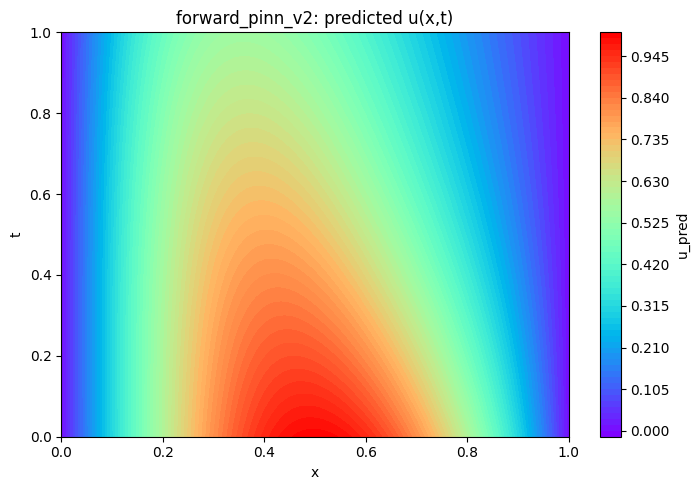

Saved: viscoelastic_pinn_outputs_v3_final/figures/fig_forward_pinn_v2_predicted_u.png


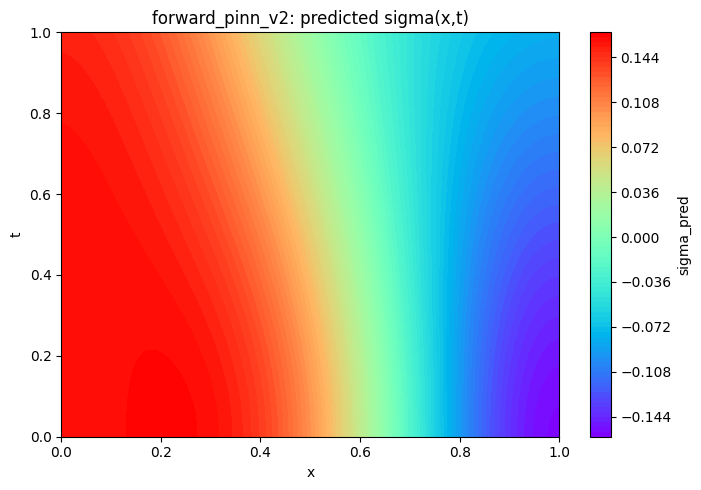

Saved: viscoelastic_pinn_outputs_v3_final/figures/fig_forward_pinn_v2_predicted_sigma.png


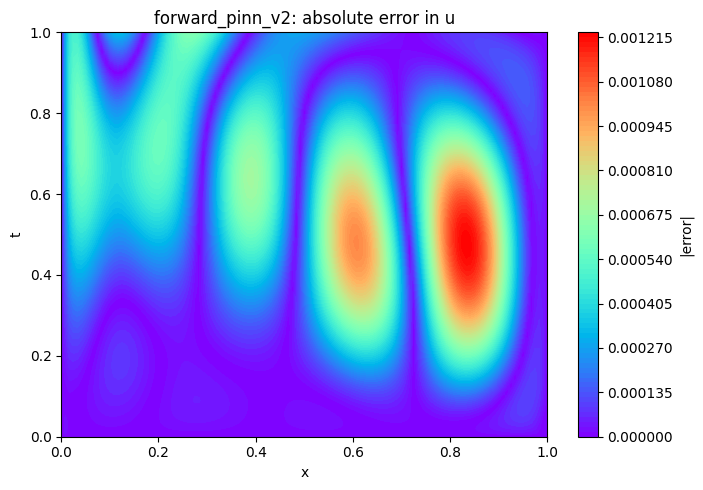

Saved: viscoelastic_pinn_outputs_v3_final/figures/fig_forward_pinn_v2_error_u.png


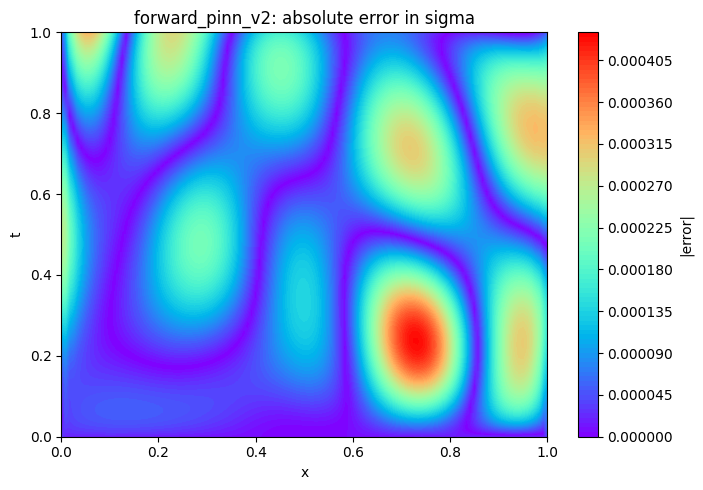

Saved: viscoelastic_pinn_outputs_v3_final/figures/fig_forward_pinn_v2_error_sigma.png
Saved: viscoelastic_pinn_outputs_v3_final/tables/table_03_forward_pinn_errors.csv


### table_03_forward_pinn_errors.csv

,tag,u_l2_relative_error,sigma_l2_relative_error,u_max_abs_error,sigma_max_abs_error,training_time_seconds,lambda_used,hard_constraints
0,forward_pinn_v2,0.00074,0.001259,0.001227,0.00043,294.300905,0.5,True


,tag,u_l2_relative_error,sigma_l2_relative_error,u_max_abs_error,sigma_max_abs_error,training_time_seconds,lambda_used,hard_constraints
0,forward_pinn_v2,0.00074,0.001259,0.001227,0.00043,294.300905,0.5,True


In [10]:
forward_metrics = None
model_forward = None

if RUN_FORWARD_PINN:
    lambda_known = PARAMS["lambda_true"]

    data_forward, pde_forward, loss_weights_forward = make_problem(
        lambda_known,
        observations=None,
        num_domain=NUM_DOMAIN,
        num_boundary=NUM_BOUNDARY,
        num_initial=NUM_INITIAL,
        num_test=NUM_TEST,
    )

    net_forward = make_network(width=80, depth=5)
    model_forward = dde.Model(data_forward, net_forward)

    history_forward, state_forward, time_forward = train_model(
        model_forward,
        adam_iters=ADAM_ITERS_FORWARD,
        lr=1e-3,
        external_vars=None,
        use_lbfgs=USE_LBFGS_MAIN,
        loss_weights=loss_weights_forward,
        display_every=1000,
    )

    forward_metrics, _ = evaluate_model(model_forward, ref, tag="forward_pinn_v2")
    forward_metrics["training_time_seconds"] = time_forward
    forward_metrics["lambda_used"] = lambda_known
    forward_metrics["hard_constraints"] = USE_HARD_CONSTRAINTS

    forward_df = pd.DataFrame([forward_metrics])
    save_table(forward_df, "table_03_forward_pinn_errors.csv")
    display(forward_df)
else:
    print("Forward PINN skipped.")

## 11. Experiment 2 — Inverse PINN with Bounded Relaxation Time

Compiling model...
'compile' took 0.000219 s

Training model...

Step      Train loss                                  Test loss                                   Test metric
0         [1.15e-01, 1.52e-01, 1.10e+00, 1.46e+00]    [1.15e-01, 1.54e-01, 1.10e+00, 1.46e+00]    []  
1000      [2.59e-04, 1.54e-04, 1.88e-03, 1.27e-04]    [2.62e-04, 1.52e-04, 1.88e-03, 1.27e-04]    []  
2000      [4.34e-05, 5.24e-05, 7.89e-05, 1.32e-05]    [4.33e-05, 5.23e-05, 7.89e-05, 1.32e-05]    []  
3000      [1.95e-05, 2.80e-05, 5.90e-05, 6.93e-06]    [1.93e-05, 2.79e-05, 5.90e-05, 6.93e-06]    []  
4000      [5.10e-04, 2.60e-04, 8.55e-04, 2.17e-03]    [5.12e-04, 2.61e-04, 8.55e-04, 2.17e-03]    []  
5000      [1.75e-04, 1.42e-04, 1.59e-04, 9.83e-04]    [1.75e-04, 1.42e-04, 1.59e-04, 9.83e-04]    []  
6000      [8.55e-06, 5.60e-06, 3.53e-05, 2.78e-06]    [8.34e-06, 5.48e-06, 3.53e-05, 2.78e-06]    []  
7000      [9.68e-06, 7.80e-06, 3.85e-05, 2.81e-05]    [9.63e-06, 7.64e-06, 3.85e-05, 2.81e-05]    []  
8

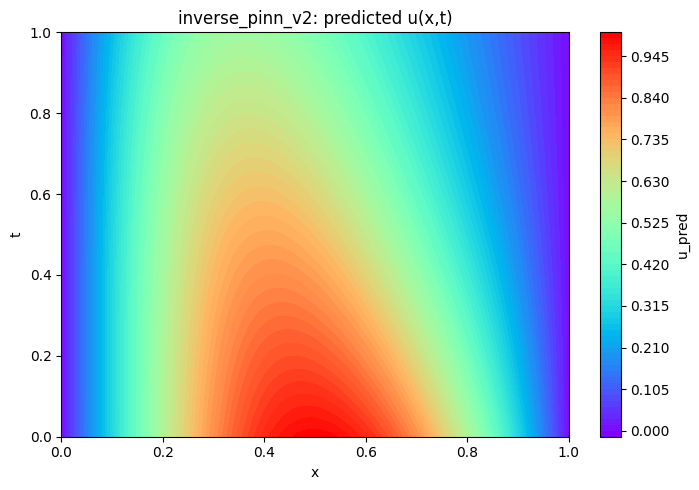

Saved: viscoelastic_pinn_outputs_v3_final/figures/fig_inverse_pinn_v2_predicted_u.png


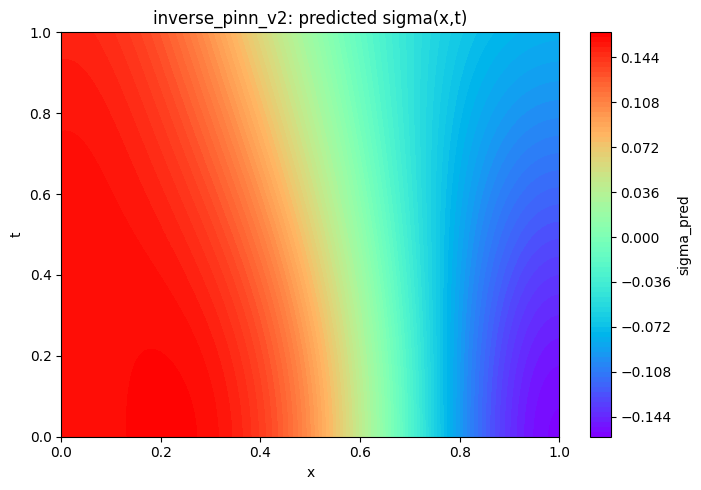

Saved: viscoelastic_pinn_outputs_v3_final/figures/fig_inverse_pinn_v2_predicted_sigma.png


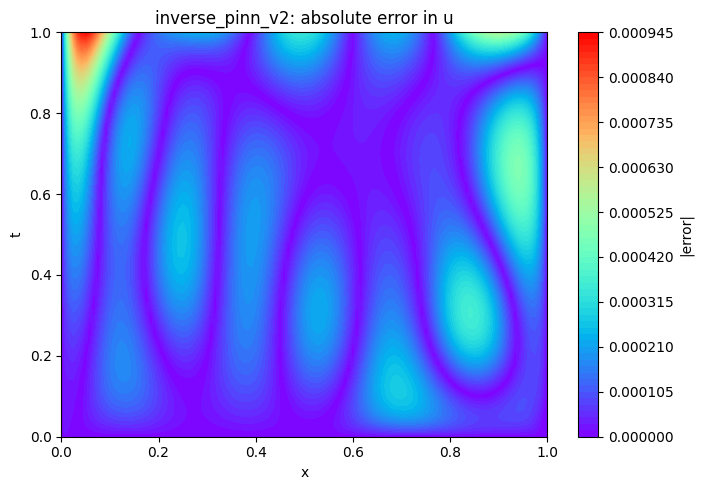

Saved: viscoelastic_pinn_outputs_v3_final/figures/fig_inverse_pinn_v2_error_u.png


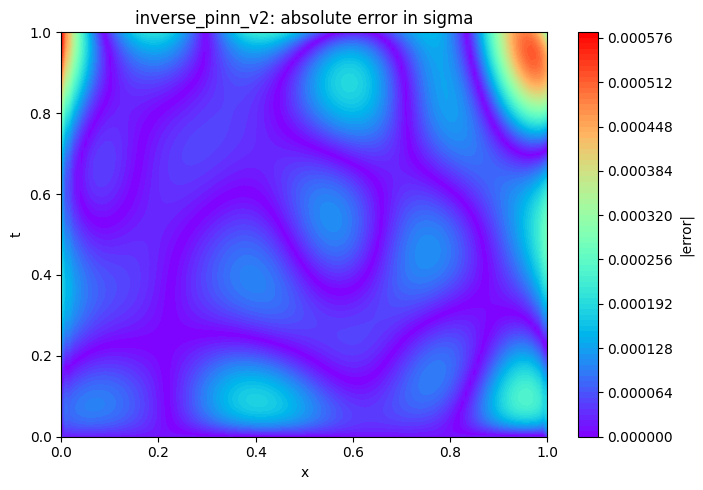

Saved: viscoelastic_pinn_outputs_v3_final/figures/fig_inverse_pinn_v2_error_sigma.png
Saved: viscoelastic_pinn_outputs_v3_final/tables/table_04_inverse_lambda_identification.csv


### table_04_inverse_lambda_identification.csv

,tag,u_l2_relative_error,sigma_l2_relative_error,u_max_abs_error,sigma_max_abs_error,n_obs,noise_level,lambda_true,lambda_initial,lambda_predicted,lambda_relative_error,training_time_seconds,lambda_raw_history_file,rar_cycles,hard_constraints,bounded_lambda
0,inverse_pinn_v2,0.000295,0.000885,0.000932,0.000579,600,0.0,0.5,0.35,0.499724,0.000552,487.728439,viscoelastic_pinn_outputs_v3_final/lambda_raw_...,0,True,True


,tag,u_l2_relative_error,sigma_l2_relative_error,u_max_abs_error,sigma_max_abs_error,n_obs,noise_level,lambda_true,lambda_initial,lambda_predicted,lambda_relative_error,training_time_seconds,lambda_raw_history_file,rar_cycles,hard_constraints,bounded_lambda
0,inverse_pinn_v2,0.000295,0.000885,0.000932,0.000579,600,0.0,0.5,0.35,0.499724,0.000552,487.728439,viscoelastic_pinn_outputs_v3_final/lambda_raw_...,0,True,True


In [11]:
def residual_score(model, X, pde_func):
    residual = model.predict(X.astype(DTYPE), operator=pde_func)
    if isinstance(residual, list):
        arrays = [np.asarray(r).reshape(len(X), -1) for r in residual]
        residual_arr = np.hstack(arrays)
    else:
        residual_arr = np.asarray(residual)
        if residual_arr.ndim == 1:
            residual_arr = residual_arr.reshape(-1, 1)
    return np.mean(np.abs(residual_arr), axis=1)


inverse_metrics = None
model_inverse = None
lambda_inverse_spec = None
data_inverse = None
pde_inverse = None
loss_weights_inverse = None

def run_inverse_case(
    n_obs=300,
    noise_level=0.0,
    lambda_init=0.35,
    adam_iters=7000,
    use_lbfgs=False,
    tag="inverse_case",
    seed=1234,
    save_figures=False,
    run_rar_cycles=0,
):
    observations = sample_observations(
        ref,
        n_obs=n_obs,
        noise_level=noise_level,
        seed=seed,
        interior_only=True,
    )

    if USE_BOUNDED_LAMBDA:
        lambda_spec = make_bounded_lambda_spec(lambda_init=lambda_init)
    else:
        lambda_spec = dde.Variable(lambda_init)

    data_inv, pde_inv, loss_weights_inv = make_problem(
        lambda_spec,
        observations=observations,
        num_domain=NUM_DOMAIN,
        num_boundary=NUM_BOUNDARY,
        num_initial=NUM_INITIAL,
        num_test=NUM_TEST,
    )

    net_inv = make_network(width=80, depth=5)
    model_inv = dde.Model(data_inv, net_inv)

    external_vars = lambda_external_variables(lambda_spec)
    var_file = str(OUTDIR / f"lambda_raw_history_{tag}.dat")

    callbacks = []
    if external_vars is not None:
        callbacks.append(dde.callbacks.VariableValue(external_vars, period=500, filename=var_file))

    hist, state, elapsed = train_model(
        model_inv,
        adam_iters=adam_iters,
        lr=1e-3,
        external_vars=external_vars,
        callbacks=callbacks,
        use_lbfgs=use_lbfgs,
        loss_weights=loss_weights_inv,
        display_every=1000,
    )

    rar_rows = []
    for cycle in range(1, run_rar_cycles + 1):
        X_candidates = geomtime.random_points(RAR_CANDIDATES).astype(DTYPE)
        scores = residual_score(model_inv, X_candidates, pde_inv)
        top_ids = np.argsort(scores)[-RAR_ADD_POINTS:]
        new_anchors = X_candidates[top_ids]
        data_inv.add_anchors(new_anchors)

        _, _, elapsed_rar = train_model(
            model_inv,
            adam_iters=ADAM_ITERS_RAR,
            lr=5e-4,
            external_vars=external_vars,
            callbacks=None,
            use_lbfgs=False,
            loss_weights=loss_weights_inv,
            display_every=1000,
        )

        rar_rows.append({
            "tag": tag,
            "cycle": cycle,
            "mean_candidate_residual": float(np.mean(scores)),
            "max_candidate_residual": float(np.max(scores)),
            "anchors_added": RAR_ADD_POINTS,
            "rar_training_time_seconds": elapsed_rar,
        })

    lambda_pred = lambda_spec_to_float(lambda_spec)
    metrics, pred_df = evaluate_model(model_inv, ref, tag=tag, save_figures=save_figures)

    metrics.update({
        "n_obs": n_obs,
        "noise_level": noise_level,
        "lambda_true": PARAMS["lambda_true"],
        "lambda_initial": lambda_init,
        "lambda_predicted": lambda_pred,
        "lambda_relative_error": abs(lambda_pred - PARAMS["lambda_true"]) / PARAMS["lambda_true"],
        "training_time_seconds": elapsed,
        "lambda_raw_history_file": var_file,
        "rar_cycles": run_rar_cycles,
        "hard_constraints": USE_HARD_CONSTRAINTS,
        "bounded_lambda": USE_BOUNDED_LAMBDA,
    })

    return {
        "model": model_inv,
        "data": data_inv,
        "pde": pde_inv,
        "loss_weights": loss_weights_inv,
        "lambda_spec": lambda_spec,
        "observations": observations,
        "metrics": metrics,
        "prediction_df": pred_df,
        "history": hist,
        "state": state,
        "rar_rows": rar_rows,
    }


if RUN_INVERSE_PINN:
    inverse_result = run_inverse_case(
        n_obs=600 if RUN_MODE != "quick" else 300,
        noise_level=0.0,
        lambda_init=0.35,
        adam_iters=ADAM_ITERS_INVERSE,
        use_lbfgs=USE_LBFGS_MAIN,
        tag="inverse_pinn_v2",
        seed=SEED + 1,
        save_figures=True,
        run_rar_cycles=0,
    )

    model_inverse = inverse_result["model"]
    data_inverse = inverse_result["data"]
    pde_inverse = inverse_result["pde"]
    loss_weights_inverse = inverse_result["loss_weights"]
    lambda_inverse_spec = inverse_result["lambda_spec"]
    inverse_metrics = inverse_result["metrics"]

    inverse_df = pd.DataFrame([inverse_metrics])
    save_table(inverse_df, "table_04_inverse_lambda_identification.csv")
    display(inverse_df)
else:
    print("Inverse PINN skipped.")

## 12. Lambda Convergence Plot

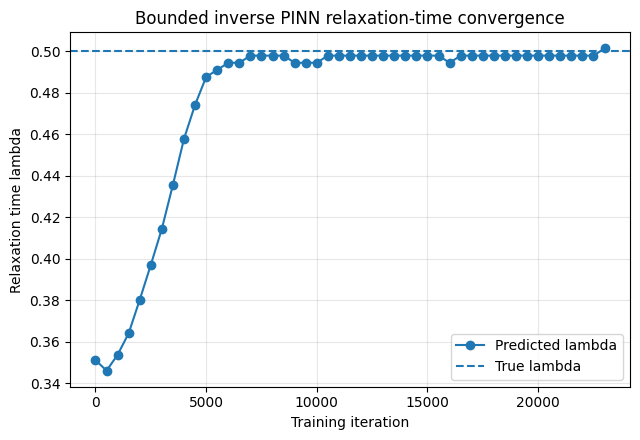

Saved: viscoelastic_pinn_outputs_v3_final/figures/fig_inverse_lambda_convergence_v2.png


In [12]:
if inverse_metrics is not None:
    raw_hist = read_variable_history(inverse_metrics["lambda_raw_history_file"])
    if raw_hist is not None:
        lambda_hist = transform_raw_history_to_lambda(raw_hist)
        epochs = np.arange(len(lambda_hist)) * 500

        plt.figure(figsize=(6.5, 4.5))
        plt.plot(epochs, lambda_hist, marker="o", label="Predicted lambda")
        plt.axhline(PARAMS["lambda_true"], linestyle="--", label="True lambda")
        plt.xlabel("Training iteration")
        plt.ylabel("Relaxation time lambda")
        plt.title("Bounded inverse PINN relaxation-time convergence")
        plt.grid(True, alpha=0.3)
        plt.legend()
        plt.tight_layout()
        path = FIGDIR / "fig_inverse_lambda_convergence_v2.png"
        plt.savefig(path, dpi=300, bbox_inches="tight")
        plt.show()
        print("Saved:", path)
    else:
        print("Lambda raw history not found.")

## 13. Experiment 3 — Sparse-Data Study with Optional Repeats


Sparse study: n_obs=50, repeat=1/2
Compiling model...
'compile' took 0.000214 s

Training model...

Step      Train loss                                  Test loss                                   Test metric
0         [2.46e-01, 3.06e-03, 1.19e+00, 9.43e-02]    [2.49e-01, 3.08e-03, 1.19e+00, 9.43e-02]    []  
1000      [2.83e-04, 1.21e-04, 6.95e-04, 1.14e-04]    [2.80e-04, 1.19e-04, 6.95e-04, 1.14e-04]    []  
2000      [4.30e-05, 2.16e-05, 1.46e-04, 5.61e-06]    [4.16e-05, 2.08e-05, 1.46e-04, 5.61e-06]    []  
3000      [1.99e-05, 9.68e-06, 9.40e-05, 4.32e-06]    [1.91e-05, 9.15e-06, 9.40e-05, 4.32e-06]    []  
4000      [3.12e-05, 8.79e-05, 1.35e-04, 5.90e-04]    [3.03e-05, 8.89e-05, 1.35e-04, 5.90e-04]    []  
5000      [1.54e-05, 6.33e-06, 5.34e-05, 9.08e-06]    [1.51e-05, 6.05e-06, 5.34e-05, 9.08e-06]    []  
6000      [1.11e-05, 4.14e-06, 4.03e-05, 3.32e-06]    [1.07e-05, 3.87e-06, 4.03e-05, 3.32e-06]    []  
7000      [1.88e-05, 9.05e-06, 6.32e-05, 3.80e-05]    [1.85e-05, 9.0

### table_05a_sparse_data_raw.csv

,tag,u_l2_relative_error,sigma_l2_relative_error,u_max_abs_error,sigma_max_abs_error,n_obs,noise_level,lambda_true,lambda_initial,lambda_predicted,lambda_relative_error,training_time_seconds,lambda_raw_history_file,rar_cycles,hard_constraints,bounded_lambda,repeat
0,sparse_v2_50_rep0,0.000579,0.001401,0.001409,0.000745,50,0.0,0.5,0.35,0.499834,0.000332,211.433233,viscoelastic_pinn_outputs_v3_final/lambda_raw_...,1,True,True,0
1,sparse_v2_50_rep1,0.000570,0.001808,0.001253,0.000777,50,0.0,0.5,0.35,0.499705,0.000589,210.760487,viscoelastic_pinn_outputs_v3_final/lambda_raw_...,1,True,True,1
2,sparse_v2_100_rep0,0.000831,0.002253,0.002718,0.001066,100,0.0,0.5,0.35,0.500985,0.001970,210.521874,viscoelastic_pinn_outputs_v3_final/lambda_raw_...,1,True,True,0
3,sparse_v2_100_rep1,0.001057,0.002450,0.002534,0.001017,100,0.0,0.5,0.35,0.502341,0.004683,212.102114,viscoelastic_pinn_outputs_v3_final/lambda_raw_...,1,True,True,1
4,sparse_v2_200_rep0,0.001346,0.007341,0.002140,0.002432,200,0.0,0.5,0.35,0.500800,0.001599,216.726913,viscoelastic_pinn_outputs_v3_final/lambda_raw_...,1,True,True,0
5,sparse_v2_200_rep1,0.000733,0.001904,0.002104,0.000832,200,0.0,0.5,0.35,0.500838,0.001676,215.149278,viscoelastic_pinn_outputs_v3_final/lambda_raw_...,1,True,True,1
6,sparse_v2_500_rep0,0.001288,0.003594,0.001639,0.001198,500,0.0,0.5,0.35,0.500054,0.000109,217.865699,viscoelastic_pinn_outputs_v3_final/lambda_raw_...,1,True,True,0
7,sparse_v2_500_rep1,0.000721,0.002387,0.002254,0.000826,500,0.0,0.5,0.35,0.502698,0.005397,217.253325,viscoelastic_pinn_outputs_v3_final/lambda_raw_...,1,True,True,1
8,sparse_v2_1000_rep0,0.003908,0.033932,0.005282,0.009569,1000,0.0,0.5,0.35,0.500469,0.000938,225.848341,viscoelastic_pinn_outputs_v3_final/lambda_raw_...,1,True,True,0
9,sparse_v2_1000_rep1,0.001424,0.006203,0.002171,0.001960,1000,0.0,0.5,0.35,0.501701,0.003403,225.160982,viscoelastic_pinn_outputs_v3_final/lambda_raw_...,1,True,True,1


Saved: viscoelastic_pinn_outputs_v3_final/tables/table_05b_sparse_data_summary.csv


### table_05b_sparse_data_summary.csv

,n_obs,lambda_predicted_mean,lambda_predicted_std,lambda_relative_error_mean,lambda_relative_error_std,u_l2_relative_error_mean,u_l2_relative_error_std,sigma_l2_relative_error_mean,sigma_l2_relative_error_std,training_time_seconds_mean,training_time_seconds_std
0,50,0.499770,0.000091,0.000461,0.000181,0.000575,0.000007,0.001605,0.000288,211.096860,0.475703
1,100,0.501663,0.000959,0.003326,0.001918,0.000944,0.000160,0.002352,0.000139,211.311994,1.117398
2,200,0.500819,0.000027,0.001638,0.000055,0.001040,0.000433,0.004622,0.003845,215.938095,1.115556
3,500,0.501376,0.001870,0.002753,0.003739,0.001005,0.000400,0.002990,0.000853,217.559512,0.433013
4,1000,0.501085,0.000871,0.002170,0.001743,0.002666,0.001757,0.020068,0.019607,225.504661,0.486036


,n_obs,repeat,lambda_true,lambda_predicted,lambda_relative_error,u_l2_relative_error,sigma_l2_relative_error
0,50,0,0.5,0.499834,0.000332,0.000579,0.001401
1,50,1,0.5,0.499705,0.000589,0.000570,0.001808
2,100,0,0.5,0.500985,0.001970,0.000831,0.002253
3,100,1,0.5,0.502341,0.004683,0.001057,0.002450
4,200,0,0.5,0.500800,0.001599,0.001346,0.007341
5,200,1,0.5,0.500838,0.001676,0.000733,0.001904
6,500,0,0.5,0.500054,0.000109,0.001288,0.003594
7,500,1,0.5,0.502698,0.005397,0.000721,0.002387
8,1000,0,0.5,0.500469,0.000938,0.003908,0.033932
9,1000,1,0.5,0.501701,0.003403,0.001424,0.006203


,n_obs,lambda_predicted_mean,lambda_predicted_std,lambda_relative_error_mean,lambda_relative_error_std,u_l2_relative_error_mean,u_l2_relative_error_std,sigma_l2_relative_error_mean,sigma_l2_relative_error_std,training_time_seconds_mean,training_time_seconds_std
0,50,0.499770,0.000091,0.000461,0.000181,0.000575,0.000007,0.001605,0.000288,211.096860,0.475703
1,100,0.501663,0.000959,0.003326,0.001918,0.000944,0.000160,0.002352,0.000139,211.311994,1.117398
2,200,0.500819,0.000027,0.001638,0.000055,0.001040,0.000433,0.004622,0.003845,215.938095,1.115556
3,500,0.501376,0.001870,0.002753,0.003739,0.001005,0.000400,0.002990,0.000853,217.559512,0.433013
4,1000,0.501085,0.000871,0.002170,0.001743,0.002666,0.001757,0.020068,0.019607,225.504661,0.486036


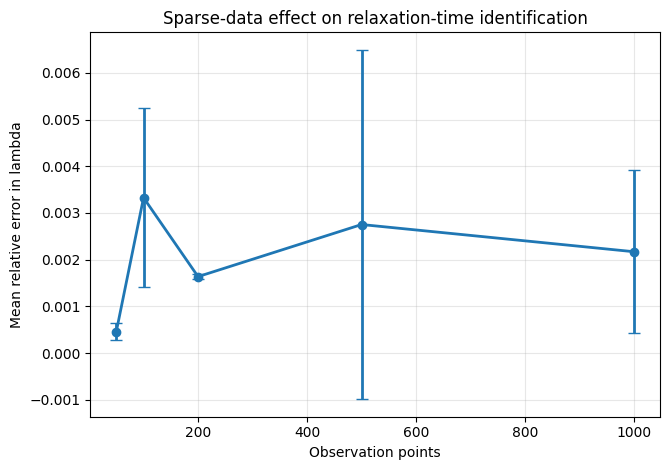

Saved: viscoelastic_pinn_outputs_v3_final/figures/fig_sparse_data_lambda_error_v2.png


In [13]:
sparse_results_df = None
sparse_summary_df = None

if RUN_SPARSE_STUDY:
    sparse_rows = []

    for n_obs in SPARSE_SIZES:
        for rep in range(STUDY_REPEATS):
            seed = SEED + 1000 + 31 * n_obs + rep
            print("\n" + "=" * 80)
            print(f"Sparse study: n_obs={n_obs}, repeat={rep+1}/{STUDY_REPEATS}")
            print("=" * 80)

            res = run_inverse_case(
                n_obs=n_obs,
                noise_level=0.0,
                lambda_init=0.35,
                adam_iters=ADAM_ITERS_STUDY,
                use_lbfgs=USE_LBFGS_STUDIES,
                tag=f"sparse_v2_{n_obs}_rep{rep}",
                seed=seed,
                save_figures=False,
                run_rar_cycles=STUDY_RAR_CYCLES,
            )
            row = res["metrics"]
            row["repeat"] = rep
            sparse_rows.append(row)

    sparse_results_df = pd.DataFrame(sparse_rows)
    sparse_summary_df = aggregate_results(sparse_results_df, ["n_obs"])

    save_table(sparse_results_df, "table_05a_sparse_data_raw.csv")
    save_table(sparse_summary_df, "table_05b_sparse_data_summary.csv")

    display(sparse_results_df[[
        "n_obs", "repeat", "lambda_true", "lambda_predicted", "lambda_relative_error",
        "u_l2_relative_error", "sigma_l2_relative_error"
    ]])
    display(sparse_summary_df)

    if STUDY_REPEATS > 1:
        plot_errorbar(
            sparse_summary_df,
            "n_obs",
            "lambda_relative_error_mean",
            "lambda_relative_error_std",
            "Sparse-data effect on relaxation-time identification",
            "Observation points",
            "Mean relative error in lambda",
            "fig_sparse_data_lambda_error_v2.png",
        )
    else:
        plot_curve(
            sparse_results_df["n_obs"],
            sparse_results_df["lambda_relative_error"],
            "Sparse-data effect on relaxation-time identification",
            "Observation points",
            "Relative error in lambda",
            "fig_sparse_data_lambda_error_v2.png",
        )
else:
    print("Sparse-data study skipped.")

## 14. Experiment 4 — Noisy-Data Robustness Study with Optional Repeats


Noise study: noise=0.0%, repeat=1/2
Compiling model...
'compile' took 0.000199 s

Training model...

Step      Train loss                                  Test loss                                   Test metric
0         [2.26e-01, 2.26e-01, 1.27e+00, 1.95e+00]    [2.26e-01, 2.29e-01, 1.27e+00, 1.95e+00]    []  
1000      [2.76e-04, 1.19e-04, 5.33e-04, 7.24e-05]    [2.79e-04, 1.20e-04, 5.33e-04, 7.24e-05]    []  
2000      [3.26e-05, 5.61e-05, 1.08e-04, 7.10e-06]    [3.25e-05, 5.63e-05, 1.08e-04, 7.10e-06]    []  
3000      [1.56e-05, 3.26e-05, 6.59e-05, 3.97e-06]    [1.57e-05, 3.25e-05, 6.59e-05, 3.97e-06]    []  
4000      [3.13e-05, 1.19e-05, 5.98e-05, 3.33e-05]    [3.15e-05, 1.18e-05, 5.98e-05, 3.33e-05]    []  
5000      [2.01e-05, 1.41e-05, 4.86e-05, 3.70e-05]    [2.05e-05, 1.42e-05, 4.86e-05, 3.70e-05]    []  
6000      [7.83e-06, 3.76e-06, 3.55e-05, 1.68e-06]    [7.82e-06, 3.68e-06, 3.55e-05, 1.68e-06]    []  
7000      [9.89e-06, 4.77e-06, 3.30e-05, 1.40e-05]    [9.97e-06, 4.

### table_06a_noise_robustness_raw.csv

,tag,u_l2_relative_error,sigma_l2_relative_error,u_max_abs_error,sigma_max_abs_error,n_obs,noise_level,lambda_true,lambda_initial,lambda_predicted,lambda_relative_error,training_time_seconds,lambda_raw_history_file,rar_cycles,hard_constraints,bounded_lambda,repeat
0,noise_v2_0pct_rep0,0.000609,0.001641,0.001803,0.000627,900,0.00,0.5,0.35,0.500360,0.000720,223.992039,viscoelastic_pinn_outputs_v3_final/lambda_raw_...,1,True,True,0
1,noise_v2_0pct_rep1,0.000681,0.001872,0.001879,0.000891,900,0.00,0.5,0.35,0.500971,0.001943,222.467586,viscoelastic_pinn_outputs_v3_final/lambda_raw_...,1,True,True,1
2,noise_v2_1pct_rep0,0.001187,0.002757,0.002198,0.001039,900,0.01,0.5,0.35,0.499555,0.000890,221.615200,viscoelastic_pinn_outputs_v3_final/lambda_raw_...,1,True,True,0
3,noise_v2_1pct_rep1,0.000848,0.002797,0.001756,0.001160,900,0.01,0.5,0.35,0.502834,0.005668,221.866512,viscoelastic_pinn_outputs_v3_final/lambda_raw_...,1,True,True,1
4,noise_v2_3pct_rep0,0.001713,0.005364,0.003972,0.002262,900,0.03,0.5,0.35,0.507513,0.015026,222.405540,viscoelastic_pinn_outputs_v3_final/lambda_raw_...,1,True,True,0
5,noise_v2_3pct_rep1,0.001684,0.003083,0.004074,0.001865,900,0.03,0.5,0.35,0.498167,0.003666,222.080739,viscoelastic_pinn_outputs_v3_final/lambda_raw_...,1,True,True,1
6,noise_v2_5pct_rep0,0.002382,0.005634,0.007070,0.002392,900,0.05,0.5,0.35,0.496286,0.007428,222.589893,viscoelastic_pinn_outputs_v3_final/lambda_raw_...,1,True,True,0
7,noise_v2_5pct_rep1,0.001805,0.003144,0.004693,0.001684,900,0.05,0.5,0.35,0.498951,0.002098,223.768252,viscoelastic_pinn_outputs_v3_final/lambda_raw_...,1,True,True,1
8,noise_v2_10pct_rep0,0.002831,0.009810,0.005197,0.003538,900,0.10,0.5,0.35,0.501262,0.002524,222.920611,viscoelastic_pinn_outputs_v3_final/lambda_raw_...,1,True,True,0
9,noise_v2_10pct_rep1,0.006599,0.012312,0.012080,0.004515,900,0.10,0.5,0.35,0.474118,0.051764,222.820343,viscoelastic_pinn_outputs_v3_final/lambda_raw_...,1,True,True,1


Saved: viscoelastic_pinn_outputs_v3_final/tables/table_06b_noise_robustness_summary.csv


### table_06b_noise_robustness_summary.csv

,noise_level,lambda_predicted_mean,lambda_predicted_std,lambda_relative_error_mean,lambda_relative_error_std,u_l2_relative_error_mean,u_l2_relative_error_std,sigma_l2_relative_error_mean,sigma_l2_relative_error_std,training_time_seconds_mean,training_time_seconds_std
0,0.00,0.500666,0.000432,0.001331,0.000865,0.000645,0.000051,0.001757,0.000163,223.229813,1.077951
1,0.01,0.501194,0.002319,0.003279,0.003378,0.001017,0.000239,0.002777,0.000028,221.740856,0.177705
2,0.03,0.502840,0.006608,0.009346,0.008033,0.001699,0.000021,0.004224,0.001613,222.243140,0.229669
3,0.05,0.497619,0.001884,0.004763,0.003768,0.002094,0.000408,0.004389,0.001761,223.179073,0.833226
4,0.10,0.487690,0.019194,0.027144,0.034818,0.004715,0.002664,0.011061,0.001770,222.870477,0.070900


,noise_level,repeat,lambda_true,lambda_predicted,lambda_relative_error,u_l2_relative_error,sigma_l2_relative_error
0,0.00,0,0.5,0.500360,0.000720,0.000609,0.001641
1,0.00,1,0.5,0.500971,0.001943,0.000681,0.001872
2,0.01,0,0.5,0.499555,0.000890,0.001187,0.002757
3,0.01,1,0.5,0.502834,0.005668,0.000848,0.002797
4,0.03,0,0.5,0.507513,0.015026,0.001713,0.005364
5,0.03,1,0.5,0.498167,0.003666,0.001684,0.003083
6,0.05,0,0.5,0.496286,0.007428,0.002382,0.005634
7,0.05,1,0.5,0.498951,0.002098,0.001805,0.003144
8,0.10,0,0.5,0.501262,0.002524,0.002831,0.009810
9,0.10,1,0.5,0.474118,0.051764,0.006599,0.012312


,noise_level,lambda_predicted_mean,lambda_predicted_std,lambda_relative_error_mean,lambda_relative_error_std,u_l2_relative_error_mean,u_l2_relative_error_std,sigma_l2_relative_error_mean,sigma_l2_relative_error_std,training_time_seconds_mean,training_time_seconds_std
0,0.00,0.500666,0.000432,0.001331,0.000865,0.000645,0.000051,0.001757,0.000163,223.229813,1.077951
1,0.01,0.501194,0.002319,0.003279,0.003378,0.001017,0.000239,0.002777,0.000028,221.740856,0.177705
2,0.03,0.502840,0.006608,0.009346,0.008033,0.001699,0.000021,0.004224,0.001613,222.243140,0.229669
3,0.05,0.497619,0.001884,0.004763,0.003768,0.002094,0.000408,0.004389,0.001761,223.179073,0.833226
4,0.10,0.487690,0.019194,0.027144,0.034818,0.004715,0.002664,0.011061,0.001770,222.870477,0.070900


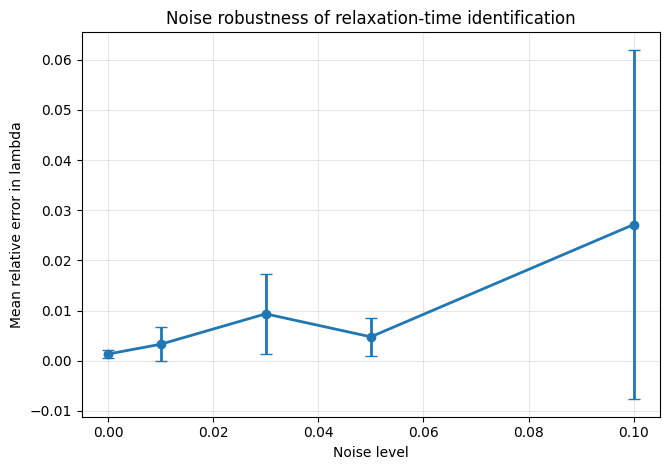

Saved: viscoelastic_pinn_outputs_v3_final/figures/fig_noise_robustness_lambda_error_v2.png


In [14]:
noise_results_df = None
noise_summary_df = None

if RUN_NOISE_STUDY:
    noise_rows = []
    n_obs_noise = 300 if RUN_MODE == "quick" else (900 if RUN_MODE in ["final", "article"] else 600)

    for noise in NOISE_LEVELS:
        for rep in range(STUDY_REPEATS):
            seed = SEED + 2000 + int(noise * 10000) + rep
            print("\n" + "=" * 80)
            print(f"Noise study: noise={noise:.1%}, repeat={rep+1}/{STUDY_REPEATS}")
            print("=" * 80)

            res = run_inverse_case(
                n_obs=n_obs_noise,
                noise_level=noise,
                lambda_init=0.35,
                adam_iters=ADAM_ITERS_STUDY,
                use_lbfgs=USE_LBFGS_STUDIES,
                tag=f"noise_v2_{int(noise*100)}pct_rep{rep}",
                seed=seed,
                save_figures=False,
                run_rar_cycles=STUDY_RAR_CYCLES,
            )
            row = res["metrics"]
            row["repeat"] = rep
            noise_rows.append(row)

    noise_results_df = pd.DataFrame(noise_rows)
    noise_summary_df = aggregate_results(noise_results_df, ["noise_level"])

    save_table(noise_results_df, "table_06a_noise_robustness_raw.csv")
    save_table(noise_summary_df, "table_06b_noise_robustness_summary.csv")

    display(noise_results_df[[
        "noise_level", "repeat", "lambda_true", "lambda_predicted", "lambda_relative_error",
        "u_l2_relative_error", "sigma_l2_relative_error"
    ]])
    display(noise_summary_df)

    if STUDY_REPEATS > 1:
        plot_errorbar(
            noise_summary_df,
            "noise_level",
            "lambda_relative_error_mean",
            "lambda_relative_error_std",
            "Noise robustness of relaxation-time identification",
            "Noise level",
            "Mean relative error in lambda",
            "fig_noise_robustness_lambda_error_v2.png",
        )
    else:
        plot_curve(
            noise_results_df["noise_level"] * 100.0,
            noise_results_df["lambda_relative_error"],
            "Noise robustness of relaxation-time identification",
            "Noise level (%)",
            "Relative error in lambda",
            "fig_noise_robustness_lambda_error_v2.png",
        )
else:
    print("Noisy-data study skipped.")

## 15. Experiment 5 — Residual-Based Adaptive Refinement, RAR

Starting RAR from trained inverse PINN.

RAR cycle 1/4
Compiling model...
'compile' took 0.001017 s

Training model...

Step      Train loss                                  Test loss                                   Test metric
22304     [2.22e-06, 3.14e-07, 4.64e-07, 1.13e-07]    [7.58e-07, 2.47e-07, 4.64e-07, 1.13e-07]    []  
23000     [1.09e-06, 3.66e-07, 5.50e-07, 1.48e-07]    [7.00e-07, 2.71e-07, 5.50e-07, 1.48e-07]    []  
24000     [8.99e-07, 3.64e-07, 5.51e-07, 1.66e-07]    [6.55e-07, 2.63e-07, 5.51e-07, 1.66e-07]    []  
25000     [8.92e-07, 3.62e-07, 5.76e-07, 1.68e-07]    [6.83e-07, 2.59e-07, 5.76e-07, 1.68e-07]    []  
26000     [8.74e-07, 3.85e-07, 5.94e-07, 1.89e-07]    [6.93e-07, 2.75e-07, 5.94e-07, 1.89e-07]    []  
27000     [8.83e-07, 3.89e-07, 5.91e-07, 1.71e-07]    [7.08e-07, 2.79e-07, 5.91e-07, 1.71e-07]    []  
28000     [1.07e-06, 5.10e-07, 1.55e-06, 1.11e-06]    [9.09e-07, 3.94e-07, 1.55e-06, 1.11e-06]    []  
28304     [9.11e-07, 4.11e-07, 6.14e-07, 1.75e-07

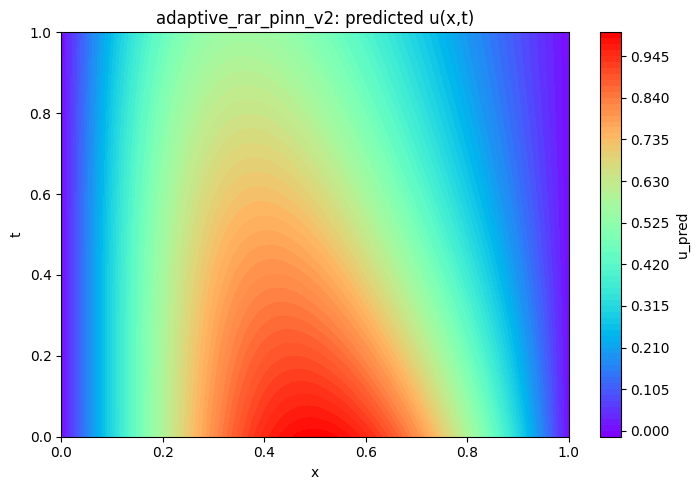

Saved: viscoelastic_pinn_outputs_v3_final/figures/fig_adaptive_rar_pinn_v2_predicted_u.png


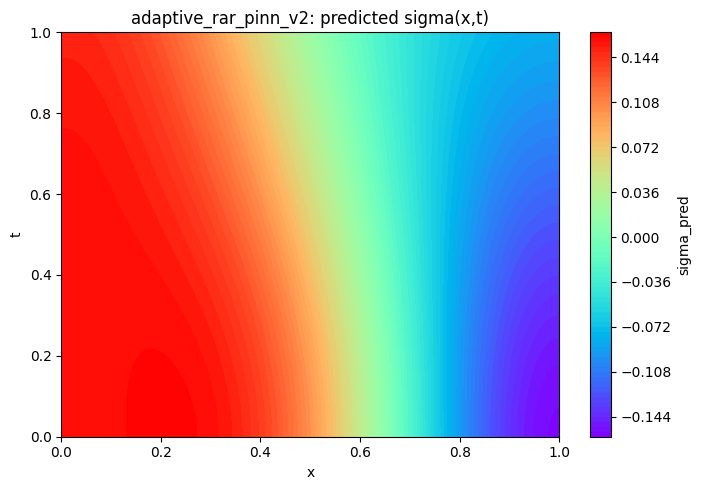

Saved: viscoelastic_pinn_outputs_v3_final/figures/fig_adaptive_rar_pinn_v2_predicted_sigma.png


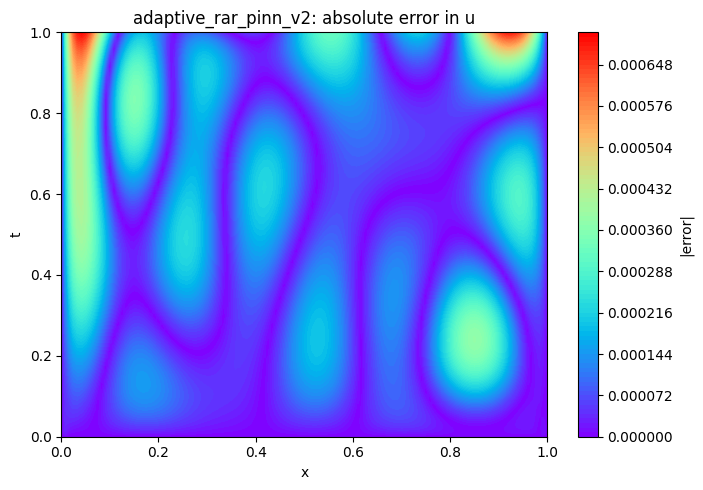

Saved: viscoelastic_pinn_outputs_v3_final/figures/fig_adaptive_rar_pinn_v2_error_u.png


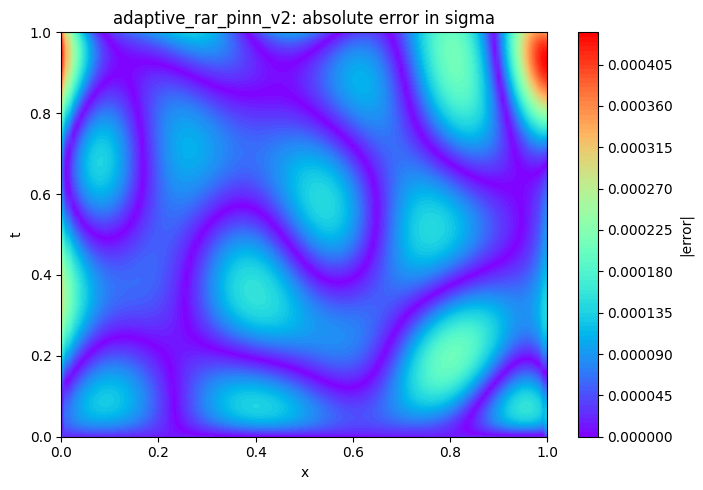

Saved: viscoelastic_pinn_outputs_v3_final/figures/fig_adaptive_rar_pinn_v2_error_sigma.png
Saved: viscoelastic_pinn_outputs_v3_final/tables/table_07_standard_vs_adaptive_rar.csv


### table_07_standard_vs_adaptive_rar.csv

,tag,u_l2_relative_error,sigma_l2_relative_error,u_max_abs_error,sigma_max_abs_error,method,lambda_predicted,lambda_relative_error
0,before_rar_v2,0.000295,0.000885,0.000932,0.000579,Standard inverse PINN before RAR,0.499724,0.000552
1,adaptive_rar_pinn_v2,0.000284,0.000808,0.000699,0.000439,Adaptive inverse PINN after RAR,0.498871,0.002257


,method,lambda_predicted,lambda_relative_error,u_l2_relative_error,sigma_l2_relative_error,u_max_abs_error,sigma_max_abs_error
0,Standard inverse PINN before RAR,0.499724,0.000552,0.000295,0.000885,0.000932,0.000579
1,Adaptive inverse PINN after RAR,0.498871,0.002257,0.000284,0.000808,0.000699,0.000439


Saved: viscoelastic_pinn_outputs_v3_final/tables/table_08_rar_history.csv


### table_08_rar_history.csv

,cycle,mean_candidate_residual,max_candidate_residual,anchors_added
0,1,0.000486,0.005226,600
1,2,0.000547,0.003159,600
2,3,0.000591,0.002521,600
3,4,0.000547,0.002391,600


,cycle,mean_candidate_residual,max_candidate_residual,anchors_added
0,1,0.000486,0.005226,600
1,2,0.000547,0.003159,600
2,3,0.000591,0.002521,600
3,4,0.000547,0.002391,600


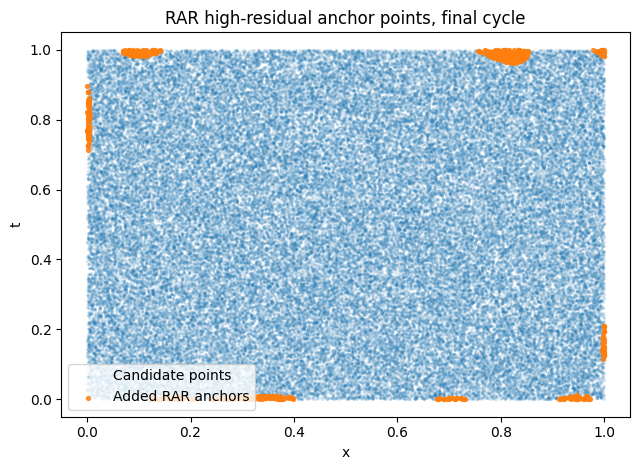

Saved: viscoelastic_pinn_outputs_v3_final/figures/fig_rar_added_anchor_points_v2.png


In [15]:
adaptive_metrics = None
rar_history_rows = []

if RUN_RAR_ADAPTIVE and model_inverse is not None:
    print("Starting RAR from trained inverse PINN.")

    before_metrics, _ = evaluate_model(model_inverse, ref, tag="before_rar_v2", save_figures=False)
    before_metrics.update({
        "method": "Standard inverse PINN before RAR",
        "lambda_predicted": lambda_spec_to_float(lambda_inverse_spec),
        "lambda_relative_error": abs(lambda_spec_to_float(lambda_inverse_spec) - PARAMS["lambda_true"]) / PARAMS["lambda_true"],
    })

    last_new_anchors = None
    last_candidates = None

    for cycle in range(1, RAR_CYCLES + 1):
        print("\n" + "=" * 80)
        print(f"RAR cycle {cycle}/{RAR_CYCLES}")
        print("=" * 80)

        X_candidates = geomtime.random_points(RAR_CANDIDATES).astype(DTYPE)
        scores = residual_score(model_inverse, X_candidates, pde_inverse)

        top_ids = np.argsort(scores)[-RAR_ADD_POINTS:]
        new_anchors = X_candidates[top_ids]
        data_inverse.add_anchors(new_anchors)

        last_new_anchors = new_anchors
        last_candidates = X_candidates

        rar_history_rows.append({
            "cycle": cycle,
            "mean_candidate_residual": float(np.mean(scores)),
            "max_candidate_residual": float(np.max(scores)),
            "anchors_added": RAR_ADD_POINTS,
        })

        _, _, elapsed_rar = train_model(
            model_inverse,
            adam_iters=ADAM_ITERS_RAR,
            lr=5e-4,
            external_vars=lambda_external_variables(lambda_inverse_spec),
            callbacks=None,
            use_lbfgs=False,
            loss_weights=loss_weights_inverse,
            display_every=1000,
        )
        print(f"RAR cycle {cycle} retraining time: {elapsed_rar:.2f} seconds")

    adaptive_metrics, _ = evaluate_model(model_inverse, ref, tag="adaptive_rar_pinn_v2", save_figures=True)
    adaptive_metrics.update({
        "method": "Adaptive inverse PINN after RAR",
        "lambda_predicted": lambda_spec_to_float(lambda_inverse_spec),
        "lambda_relative_error": abs(lambda_spec_to_float(lambda_inverse_spec) - PARAMS["lambda_true"]) / PARAMS["lambda_true"],
    })

    comparison_df = pd.DataFrame([before_metrics, adaptive_metrics])
    save_table(comparison_df, "table_07_standard_vs_adaptive_rar.csv")
    display(comparison_df[[
        "method", "lambda_predicted", "lambda_relative_error",
        "u_l2_relative_error", "sigma_l2_relative_error",
        "u_max_abs_error", "sigma_max_abs_error"
    ]])

    rar_history_df = pd.DataFrame(rar_history_rows)
    save_table(rar_history_df, "table_08_rar_history.csv")
    display(rar_history_df)

    if last_new_anchors is not None:
        plt.figure(figsize=(6.5, 4.8))
        plt.scatter(last_candidates[:, 0], last_candidates[:, 1], s=2, alpha=0.12, label="Candidate points")
        plt.scatter(last_new_anchors[:, 0], last_new_anchors[:, 1], s=8, alpha=0.8, label="Added RAR anchors")
        plt.xlabel("x")
        plt.ylabel("t")
        plt.title("RAR high-residual anchor points, final cycle")
        plt.legend()
        plt.tight_layout()
        path = FIGDIR / "fig_rar_added_anchor_points_v2.png"
        plt.savefig(path, dpi=300, bbox_inches="tight")
        plt.show()
        print("Saved:", path)
else:
    print("RAR skipped.")

## 16. Experiment 6 — Relaxation-Time Sweep


Lambda sweep: true lambda=0.2
dx=8.3333e-03, dt=7.1429e-04, diffusion CFL=5.1429e-02
Compiling model...
'compile' took 0.000199 s

Training model...

Step      Train loss                                  Test loss                                   Test metric
0         [3.71e-01, 5.26e-03, 1.30e+00, 9.97e-02]    [3.71e-01, 5.31e-03, 1.30e+00, 9.97e-02]    []  
1000      [2.63e-04, 6.73e-05, 8.82e-04, 1.12e-04]    [2.62e-04, 6.72e-05, 8.82e-04, 1.12e-04]    []  
2000      [4.36e-05, 1.69e-05, 9.62e-05, 1.96e-05]    [4.28e-05, 1.69e-05, 9.62e-05, 1.96e-05]    []  
3000      [8.26e-05, 1.66e-05, 2.27e-04, 1.73e-04]    [8.23e-05, 1.64e-05, 2.27e-04, 1.73e-04]    []  
4000      [1.72e-05, 5.15e-06, 6.33e-05, 2.09e-05]    [1.71e-05, 5.19e-06, 6.33e-05, 2.09e-05]    []  
5000      [1.05e-05, 3.31e-06, 3.55e-05, 1.43e-05]    [1.04e-05, 3.25e-06, 3.55e-05, 1.43e-05]    []  
6000      [9.09e-06, 2.78e-06, 2.66e-05, 5.36e-06]    [8.99e-06, 2.76e-06, 2.66e-05, 5.36e-06]    []  
7000      [1.27e-0

### table_09_lambda_sweep_inverse_identification.csv

,tag,u_l2_relative_error,sigma_l2_relative_error,u_max_abs_error,sigma_max_abs_error,n_obs,noise_level,lambda_true,lambda_initial,lambda_predicted,lambda_relative_error,training_time_seconds,lambda_raw_history_file,rar_cycles,hard_constraints,bounded_lambda
0,lambda_sweep_v2_0_2,0.000484,0.001862,0.001342,0.001214,900,0.0,0.20,0.35,0.198836,0.005821,223.748582,viscoelastic_pinn_outputs_v3_final/lambda_raw_...,1,True,True
1,lambda_sweep_v2_0_35,0.000810,0.004119,0.001364,0.001294,900,0.0,0.35,0.35,0.348881,0.003197,222.285259,viscoelastic_pinn_outputs_v3_final/lambda_raw_...,1,True,True
2,lambda_sweep_v2_0_5,0.001972,0.006488,0.002945,0.002875,900,0.0,0.50,0.35,0.502007,0.004014,222.568791,viscoelastic_pinn_outputs_v3_final/lambda_raw_...,1,True,True
3,lambda_sweep_v2_0_75,0.000735,0.001967,0.001832,0.001138,900,0.0,0.75,0.35,0.750761,0.001014,223.959792,viscoelastic_pinn_outputs_v3_final/lambda_raw_...,1,True,True
4,lambda_sweep_v2_1_0,0.001045,0.002966,0.001961,0.001200,900,0.0,1.00,0.35,1.000780,0.000780,223.944894,viscoelastic_pinn_outputs_v3_final/lambda_raw_...,1,True,True


,lambda_true,lambda_predicted,lambda_relative_error,u_l2_relative_error,sigma_l2_relative_error,rar_cycles
0,0.20,0.198836,0.005821,0.000484,0.001862,1
1,0.35,0.348881,0.003197,0.000810,0.004119,1
2,0.50,0.502007,0.004014,0.001972,0.006488,1
3,0.75,0.750761,0.001014,0.000735,0.001967,1
4,1.00,1.000780,0.000780,0.001045,0.002966,1


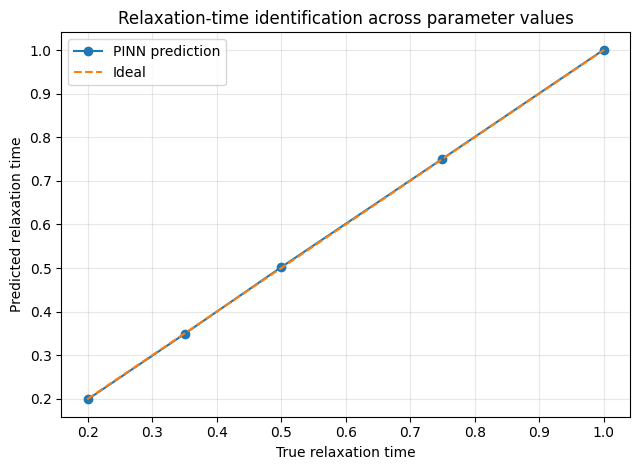

Saved: viscoelastic_pinn_outputs_v3_final/figures/fig_lambda_sweep_true_vs_predicted_v2.png


In [16]:
lambda_sweep_df = None

if RUN_LAMBDA_SWEEP:
    sweep_rows = []

    original_ref = ref
    original_lambda = PARAMS["lambda_true"]

    for lam_true in LAMBDA_SWEEP_VALUES:
        print("\n" + "=" * 80)
        print(f"Lambda sweep: true lambda={lam_true}")
        print("=" * 80)

        local_ref = generate_reference_solution(
            lambda_true=lam_true,
            rho=PARAMS["rho"],
            D=PARAMS["D"],
            eta=PARAMS["eta"],
            alpha=PARAMS["alpha"],
            L=PARAMS["L"],
            T=PARAMS["T"],
            Nx=101 if RUN_MODE == "quick" else 121,
            Nt=1001 if RUN_MODE == "quick" else 1401,
        )

        ref = local_ref
        PARAMS["lambda_true"] = lam_true

        res = run_inverse_case(
            n_obs=300 if RUN_MODE == "quick" else (900 if RUN_MODE in ["final", "article"] else 600),
            noise_level=0.0,
            lambda_init=0.35,
            adam_iters=ADAM_ITERS_STUDY,
            use_lbfgs=USE_LBFGS_STUDIES,
            tag=f"lambda_sweep_v2_{str(lam_true).replace('.', '_')}",
            seed=SEED + int(lam_true * 1000),
            save_figures=False,
            run_rar_cycles=STUDY_RAR_CYCLES,
        )
        sweep_rows.append(res["metrics"])

    ref = original_ref
    PARAMS["lambda_true"] = original_lambda

    lambda_sweep_df = pd.DataFrame(sweep_rows)
    save_table(lambda_sweep_df, "table_09_lambda_sweep_inverse_identification.csv")
    display(lambda_sweep_df[[
        "lambda_true", "lambda_predicted", "lambda_relative_error",
        "u_l2_relative_error", "sigma_l2_relative_error", "rar_cycles"
    ]])

    plt.figure(figsize=(6.5, 4.8))
    plt.plot(lambda_sweep_df["lambda_true"], lambda_sweep_df["lambda_predicted"], marker="o", label="PINN prediction")
    min_lam = min(lambda_sweep_df["lambda_true"].min(), lambda_sweep_df["lambda_predicted"].min())
    max_lam = max(lambda_sweep_df["lambda_true"].max(), lambda_sweep_df["lambda_predicted"].max())
    plt.plot([min_lam, max_lam], [min_lam, max_lam], linestyle="--", label="Ideal")
    plt.xlabel("True relaxation time")
    plt.ylabel("Predicted relaxation time")
    plt.title("Relaxation-time identification across parameter values")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    path = FIGDIR / "fig_lambda_sweep_true_vs_predicted_v2.png"
    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()
    print("Saved:", path)
else:
    print("Lambda sweep skipped.")

## 17. Quality Checks for Article Use

In [17]:
quality_rows = []

def add_quality_check(name, condition, value, threshold, recommendation):
    quality_rows.append({
        "Check": name,
        "Value": value,
        "Threshold": threshold,
        "Status": "PASS" if condition else "NEEDS IMPROVEMENT",
        "Recommendation": recommendation if not condition else "OK",
    })

if forward_metrics is not None:
    add_quality_check(
        "Forward u L2 error",
        forward_metrics["u_l2_relative_error"] < 0.02,
        forward_metrics["u_l2_relative_error"],
        "< 0.02",
        "Increase ADAM_ITERS_FORWARD, NUM_DOMAIN, or use RUN_MODE='article'."
    )

if inverse_metrics is not None:
    add_quality_check(
        "Inverse lambda error",
        inverse_metrics["lambda_relative_error"] < 0.05,
        inverse_metrics["lambda_relative_error"],
        "< 0.05",
        "Increase observations, ADAM_ITERS_INVERSE, or run RAR before reporting inverse results."
    )

if adaptive_metrics is not None:
    add_quality_check(
        "Adaptive lambda error",
        adaptive_metrics["lambda_relative_error"] < 0.03,
        adaptive_metrics["lambda_relative_error"],
        "< 0.03",
        "Increase RAR_CYCLES or use RUN_MODE='article'."
    )

if sparse_summary_df is not None:
    last = sparse_summary_df.sort_values("n_obs").iloc[-1]
    add_quality_check(
        "Sparse study best lambda error",
        last["lambda_relative_error_mean"] < 0.08,
        last["lambda_relative_error_mean"],
        "< 0.08",
        "Use more observations, more iterations, or repeats; report mean±std."
    )

if noise_summary_df is not None:
    low_noise = noise_summary_df[noise_summary_df["noise_level"] <= 0.03]
    if len(low_noise) > 0:
        worst_low = low_noise["lambda_relative_error_mean"].max()
        add_quality_check(
            "Noise robustness up to 3%",
            worst_low < 0.15,
            worst_low,
            "< 0.15",
            "Increase data loss weight, observations, or use denoising/regularization."
        )

if lambda_sweep_df is not None:
    max_sweep_err = lambda_sweep_df["lambda_relative_error"].max()
    add_quality_check(
        "Lambda sweep max error",
        max_sweep_err < 0.10,
        max_sweep_err,
        "< 0.10",
        "Use RUN_MODE='article', enable L-BFGS, or use one RAR cycle per lambda case."
    )

quality_df = pd.DataFrame(quality_rows)
save_table(quality_df, "table_10_quality_checks.csv")
display(quality_df)

Saved: viscoelastic_pinn_outputs_v3_final/tables/table_10_quality_checks.csv


### table_10_quality_checks.csv

,Check,Value,Threshold,Status,Recommendation
0,Forward u L2 error,0.000740,< 0.02,PASS,OK
1,Inverse lambda error,0.000552,< 0.05,PASS,OK
2,Adaptive lambda error,0.002257,< 0.03,PASS,OK
3,Sparse study best lambda error,0.002170,< 0.08,PASS,OK
4,Noise robustness up to 3%,0.009346,< 0.15,PASS,OK
5,Lambda sweep max error,0.005821,< 0.10,PASS,OK


,Check,Value,Threshold,Status,Recommendation
0,Forward u L2 error,0.000740,< 0.02,PASS,OK
1,Inverse lambda error,0.000552,< 0.05,PASS,OK
2,Adaptive lambda error,0.002257,< 0.03,PASS,OK
3,Sparse study best lambda error,0.002170,< 0.08,PASS,OK
4,Noise robustness up to 3%,0.009346,< 0.15,PASS,OK
5,Lambda sweep max error,0.005821,< 0.10,PASS,OK


## 18. Ablation and Final Summary

In [18]:
ablation_rows = []

if forward_metrics is not None:
    ablation_rows.append({
        "Model": "Forward hard-constrained PINN",
        "Known lambda": "Yes",
        "Trainable lambda": "No",
        "Sparse data": "No",
        "Noise": "No",
        "Adaptive RAR": "No",
        "lambda_predicted": np.nan,
        "lambda_relative_error": np.nan,
        "u_l2_relative_error": forward_metrics["u_l2_relative_error"],
        "sigma_l2_relative_error": forward_metrics["sigma_l2_relative_error"],
    })

if inverse_metrics is not None:
    ablation_rows.append({
        "Model": "Bounded inverse PINN",
        "Known lambda": "No",
        "Trainable lambda": "Yes",
        "Sparse data": "Yes",
        "Noise": "No",
        "Adaptive RAR": "No",
        "lambda_predicted": inverse_metrics["lambda_predicted"],
        "lambda_relative_error": inverse_metrics["lambda_relative_error"],
        "u_l2_relative_error": inverse_metrics["u_l2_relative_error"],
        "sigma_l2_relative_error": inverse_metrics["sigma_l2_relative_error"],
    })

if adaptive_metrics is not None:
    ablation_rows.append({
        "Model": "Adaptive bounded inverse PINN",
        "Known lambda": "No",
        "Trainable lambda": "Yes",
        "Sparse data": "Yes",
        "Noise": "No",
        "Adaptive RAR": "Yes",
        "lambda_predicted": adaptive_metrics["lambda_predicted"],
        "lambda_relative_error": adaptive_metrics["lambda_relative_error"],
        "u_l2_relative_error": adaptive_metrics["u_l2_relative_error"],
        "sigma_l2_relative_error": adaptive_metrics["sigma_l2_relative_error"],
    })

ablation_df = pd.DataFrame(ablation_rows)
save_table(ablation_df, "table_11_ablation_summary.csv")
display(ablation_df)

summary_rows = [
    {"Experiment": "Forward PINN", "Purpose": "Validate PDE solution accuracy", "Main figure/table": "Table 03 and forward prediction/error figures"},
    {"Experiment": "Inverse PINN", "Purpose": "Recover unknown relaxation time from sparse interior data", "Main figure/table": "Table 04 and lambda convergence figure"},
    {"Experiment": "Sparse data", "Purpose": "Quantify sensitivity to number of measurements", "Main figure/table": "Table 05a/05b and sparse-data curve"},
    {"Experiment": "Noisy data", "Purpose": "Quantify robustness to measurement noise", "Main figure/table": "Table 06a/06b and noise curve"},
    {"Experiment": "Adaptive RAR", "Purpose": "Compare standard inverse PINN with adaptive residual refinement", "Main figure/table": "Table 07/08 and RAR anchor figure"},
    {"Experiment": "Lambda sweep", "Purpose": "Test inverse identification across different material relaxation times", "Main figure/table": "Table 09 and true-vs-predicted lambda figure"},
]
summary_df = pd.DataFrame(summary_rows)
save_table(summary_df, "table_12_final_article_summary.csv")
display(summary_df)

Saved: viscoelastic_pinn_outputs_v3_final/tables/table_11_ablation_summary.csv


### table_11_ablation_summary.csv

,Model,Known lambda,Trainable lambda,Sparse data,Noise,Adaptive RAR,lambda_predicted,lambda_relative_error,u_l2_relative_error,sigma_l2_relative_error
0,Forward hard-constrained PINN,Yes,No,No,No,No,NaN,NaN,0.000740,0.001259
1,Bounded inverse PINN,No,Yes,Yes,No,No,0.499724,0.000552,0.000295,0.000885
2,Adaptive bounded inverse PINN,No,Yes,Yes,No,Yes,0.498871,0.002257,0.000284,0.000808


,Model,Known lambda,Trainable lambda,Sparse data,Noise,Adaptive RAR,lambda_predicted,lambda_relative_error,u_l2_relative_error,sigma_l2_relative_error
0,Forward hard-constrained PINN,Yes,No,No,No,No,NaN,NaN,0.000740,0.001259
1,Bounded inverse PINN,No,Yes,Yes,No,No,0.499724,0.000552,0.000295,0.000885
2,Adaptive bounded inverse PINN,No,Yes,Yes,No,Yes,0.498871,0.002257,0.000284,0.000808


Saved: viscoelastic_pinn_outputs_v3_final/tables/table_12_final_article_summary.csv


### table_12_final_article_summary.csv

,Experiment,Purpose,Main figure/table
0,Forward PINN,Validate PDE solution accuracy,Table 03 and forward prediction/error figures
1,Inverse PINN,Recover unknown relaxation time from sparse in...,Table 04 and lambda convergence figure
2,Sparse data,Quantify sensitivity to number of measurements,Table 05a/05b and sparse-data curve
3,Noisy data,Quantify robustness to measurement noise,Table 06a/06b and noise curve
4,Adaptive RAR,Compare standard inverse PINN with adaptive re...,Table 07/08 and RAR anchor figure
5,Lambda sweep,Test inverse identification across different m...,Table 09 and true-vs-predicted lambda figure


,Experiment,Purpose,Main figure/table
0,Forward PINN,Validate PDE solution accuracy,Table 03 and forward prediction/error figures
1,Inverse PINN,Recover unknown relaxation time from sparse in...,Table 04 and lambda convergence figure
2,Sparse data,Quantify sensitivity to number of measurements,Table 05a/05b and sparse-data curve
3,Noisy data,Quantify robustness to measurement noise,Table 06a/06b and noise curve
4,Adaptive RAR,Compare standard inverse PINN with adaptive re...,Table 07/08 and RAR anchor figure
5,Lambda sweep,Test inverse identification across different m...,Table 09 and true-vs-predicted lambda figure


## 19. Export and Display All Article Outputs

Created ZIP: /kaggle/working/viscoelastic_pinn_outputs_v3_final.zip


# All Saved Tables

## table_01_physical_parameters.csv

,Symbol,Value
0,rho,1.000
1,D,0.005
2,eta,0.050
3,alpha,0.100
4,lambda_true,0.500
5,L,1.000
6,T,1.000
7,lambda_min,0.050
8,lambda_max,2.000


## table_02_network_hyperparameters.csv

...

,Model,Known lambda,Trainable lambda,Sparse data,Noise,Adaptive RAR,lambda_predicted,lambda_relative_error,u_l2_relative_error,sigma_l2_relative_error
0,Forward hard-constrained PINN,Yes,No,No,No,No,NaN,NaN,0.000740,0.001259
1,Bounded inverse PINN,No,Yes,Yes,No,No,0.499724,0.000552,0.000295,0.000885
2,Adaptive bounded inverse PINN,No,Yes,Yes,No,Yes,0.498871,0.002257,0.000284,0.000808


## table_12_final_article_summary.csv

,Experiment,Purpose,Main figure/table
0,Forward PINN,Validate PDE solution accuracy,Table 03 and forward prediction/error figures
1,Inverse PINN,Recover unknown relaxation time from sparse in...,Table 04 and lambda convergence figure
2,Sparse data,Quantify sensitivity to number of measurements,Table 05a/05b and sparse-data curve
3,Noisy data,Quantify robustness to measurement noise,Table 06a/06b and noise curve
4,Adaptive RAR,Compare standard inverse PINN with adaptive re...,Table 07/08 and RAR anchor figure
5,Lambda sweep,Test inverse identification across different m...,Table 09 and true-vs-predicted lambda figure


# All Saved Figures

## fig_01_reference_u.png

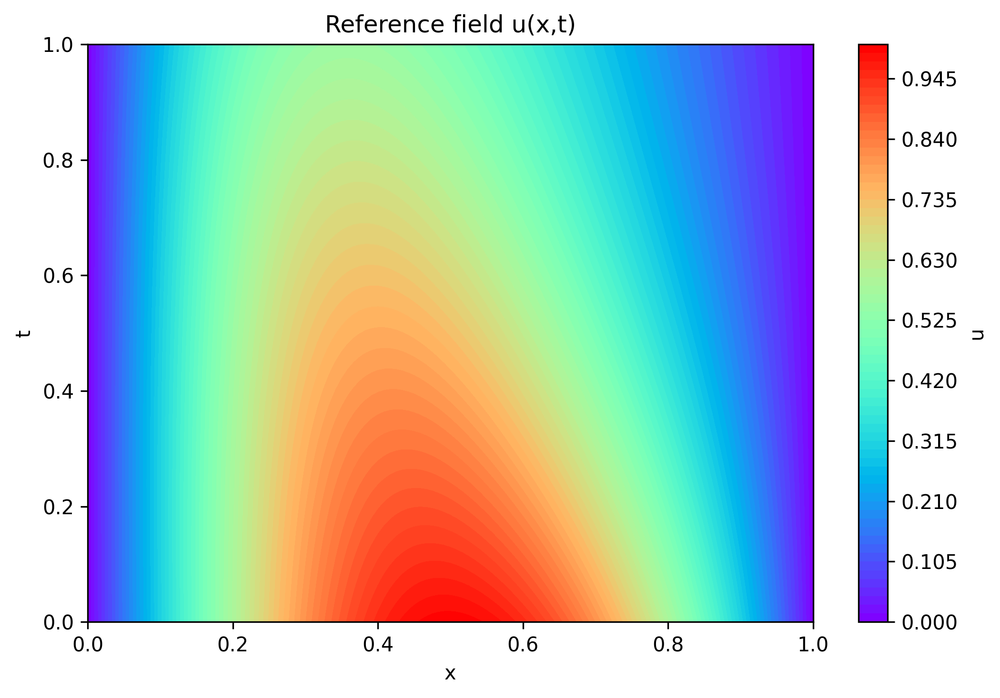

## fig_02_reference_sigma.png

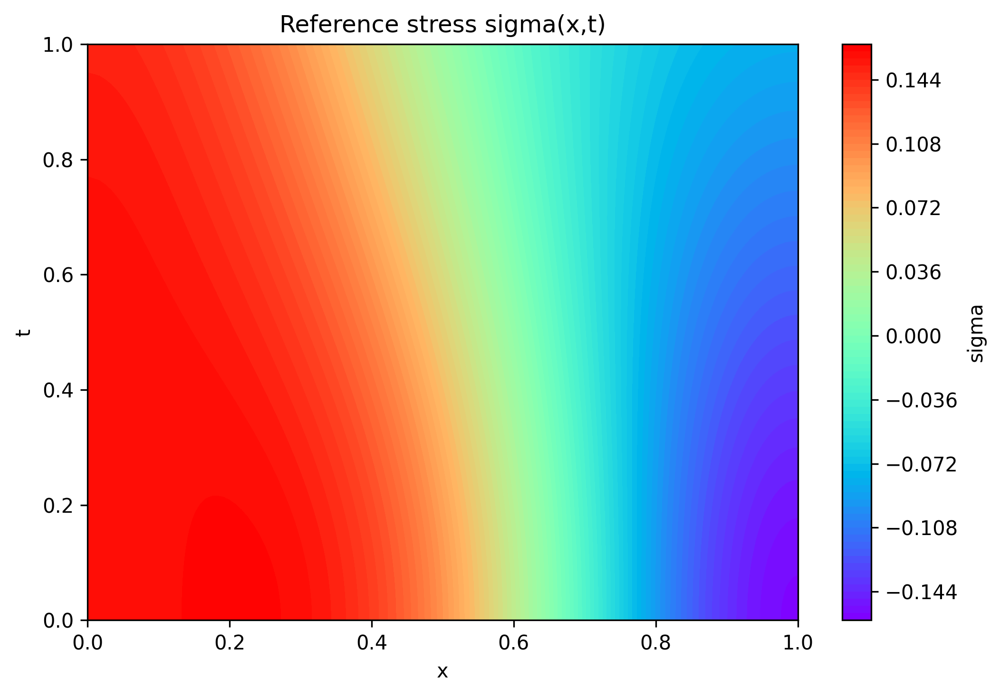

## fig_adaptive_rar_pinn_v2_error_sigma.png

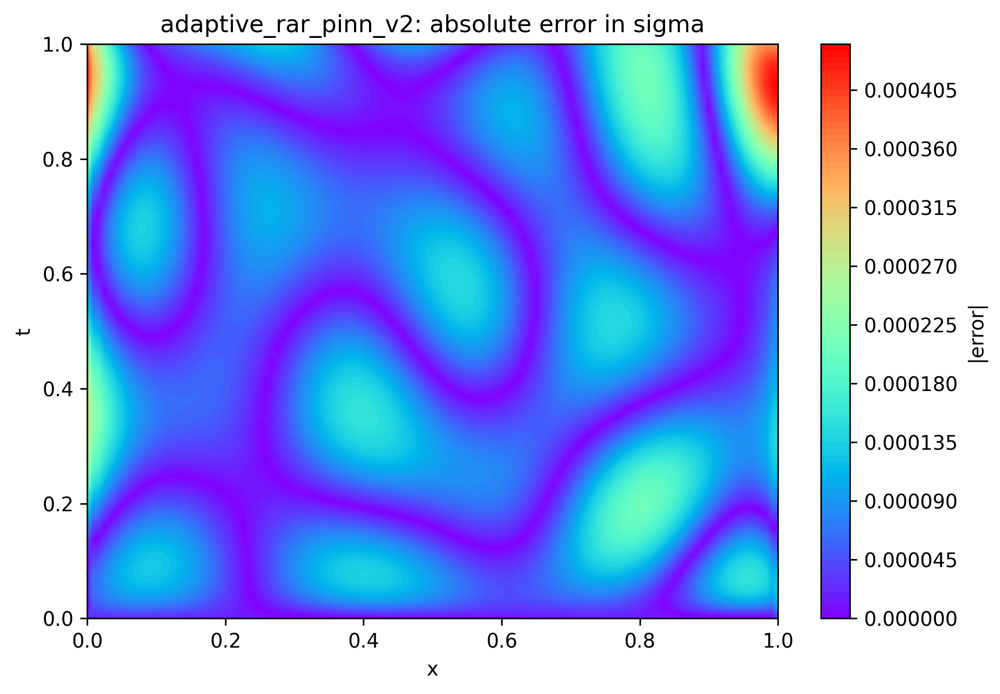

## fig_adaptive_rar_pinn_v2_error_u.png

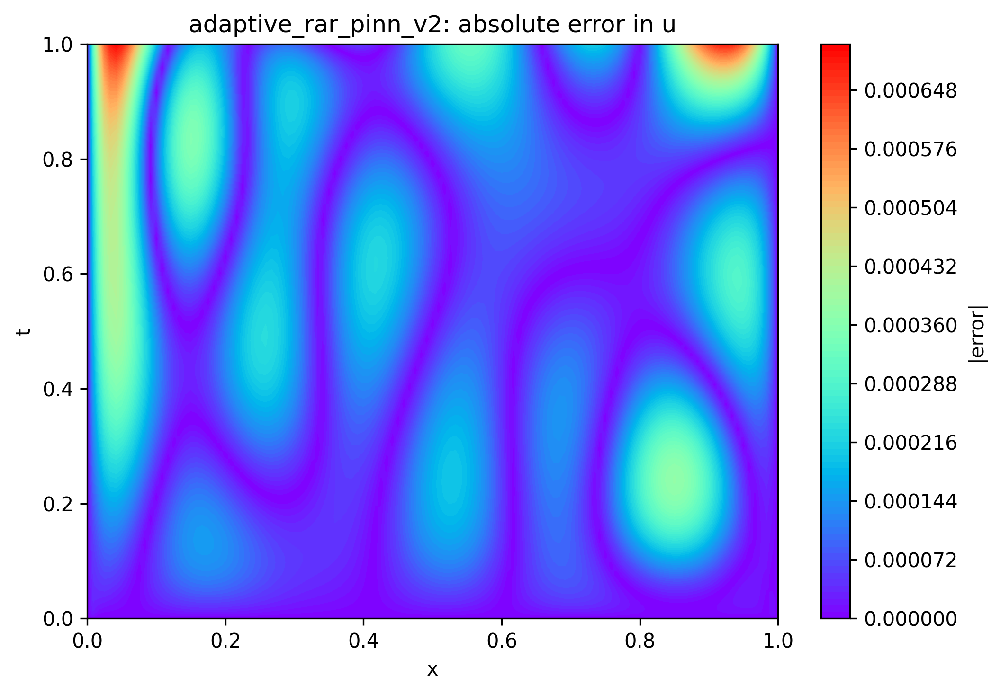

## fig_adaptive_rar_pinn_v2_predicted_sigma.png

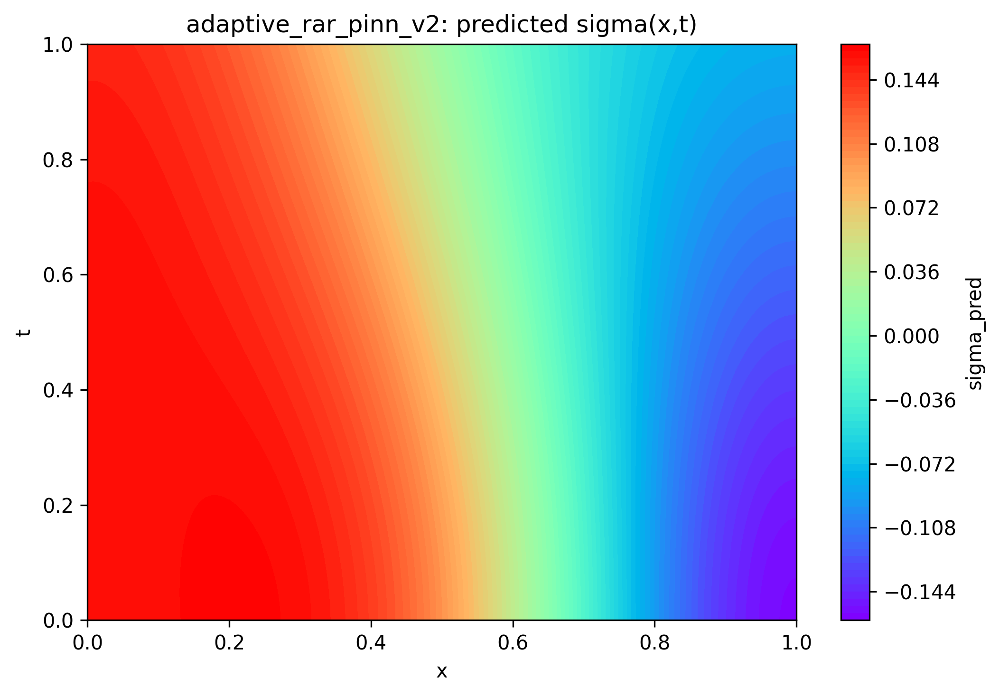

## fig_adaptive_rar_pinn_v2_predicted_u.png

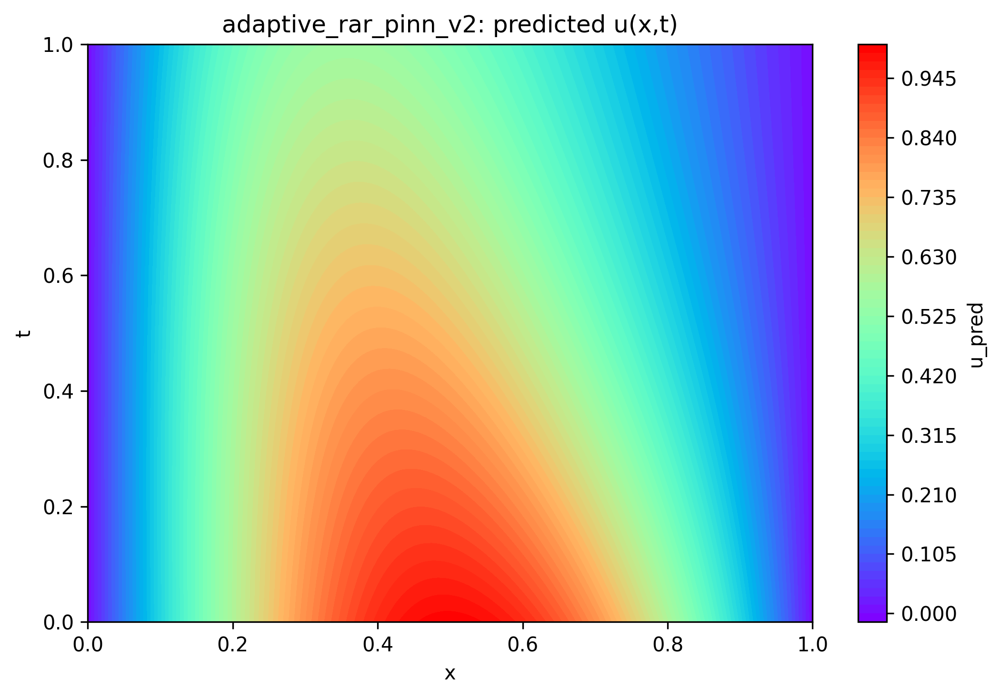

## fig_forward_pinn_v2_error_sigma.png

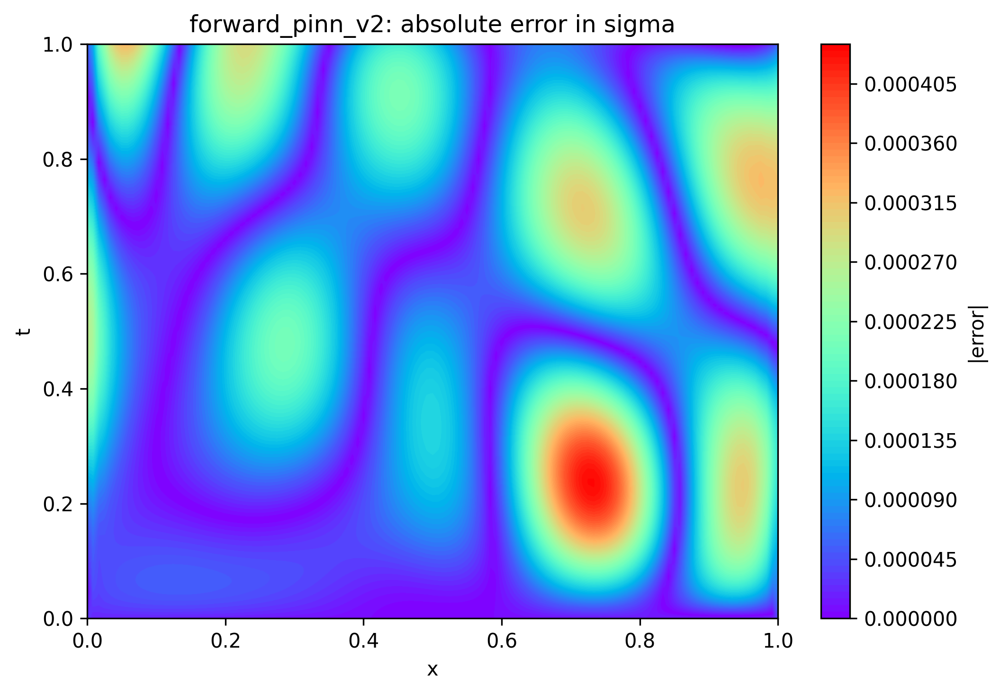

## fig_forward_pinn_v2_error_u.png

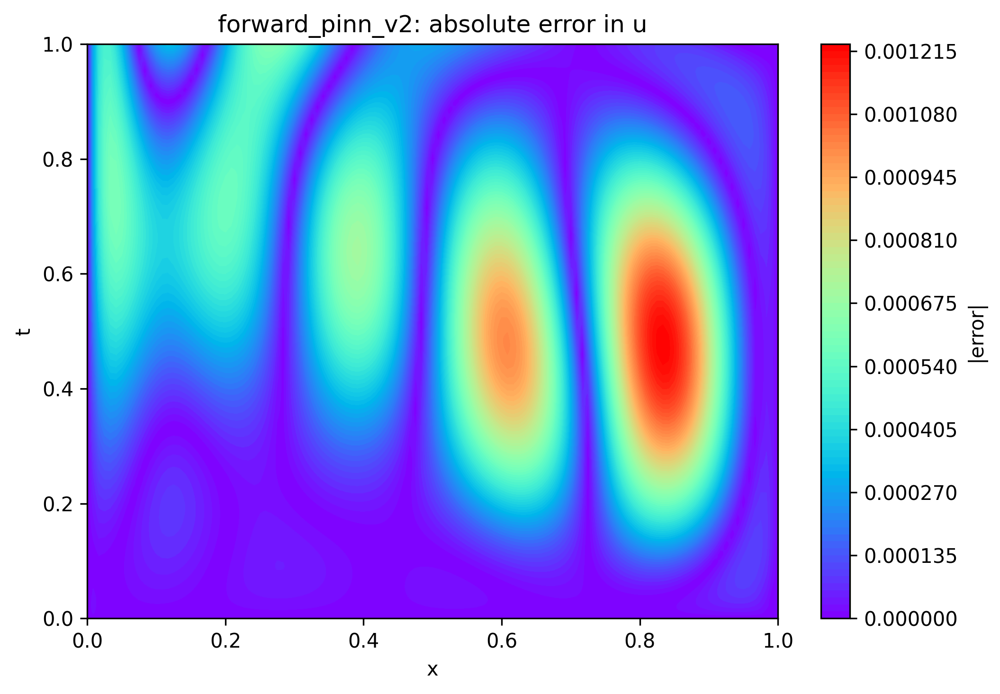

## fig_forward_pinn_v2_predicted_sigma.png

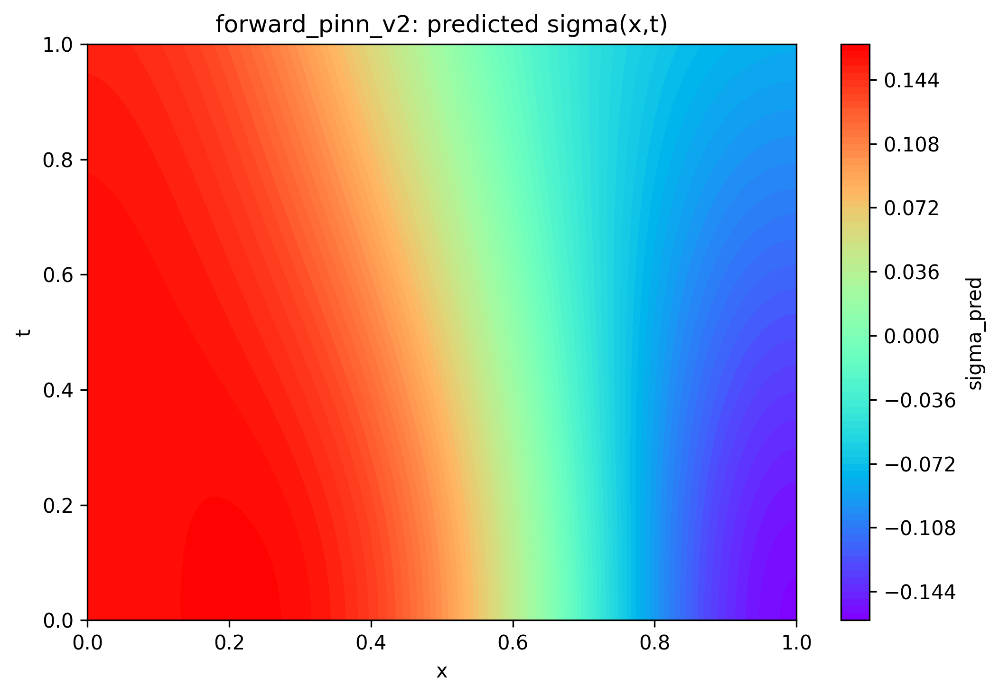

## fig_forward_pinn_v2_predicted_u.png

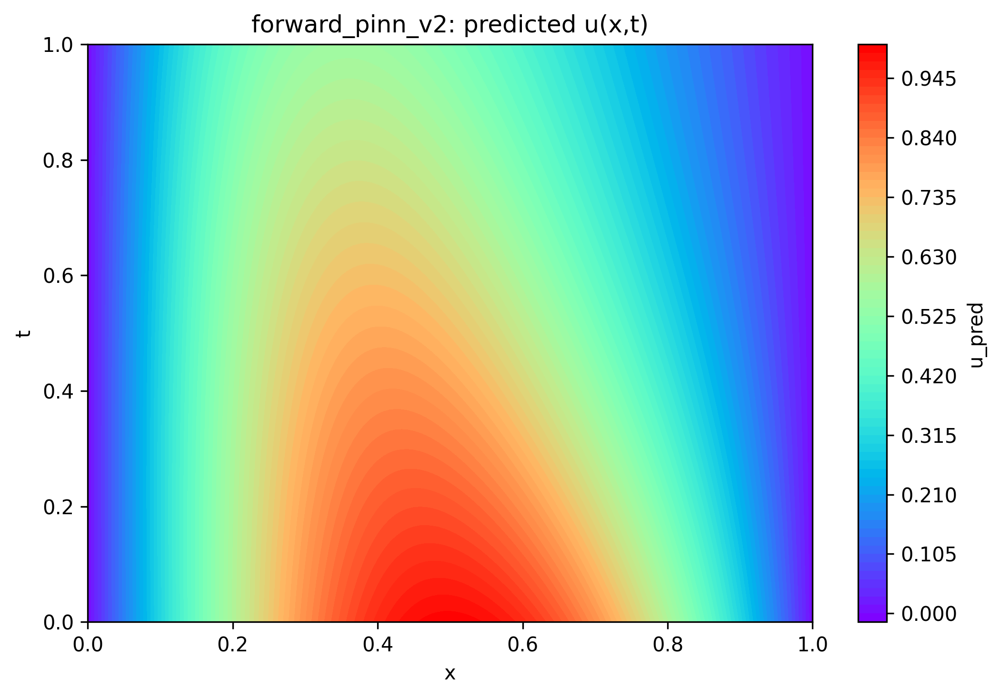

## fig_inverse_lambda_convergence_v2.png

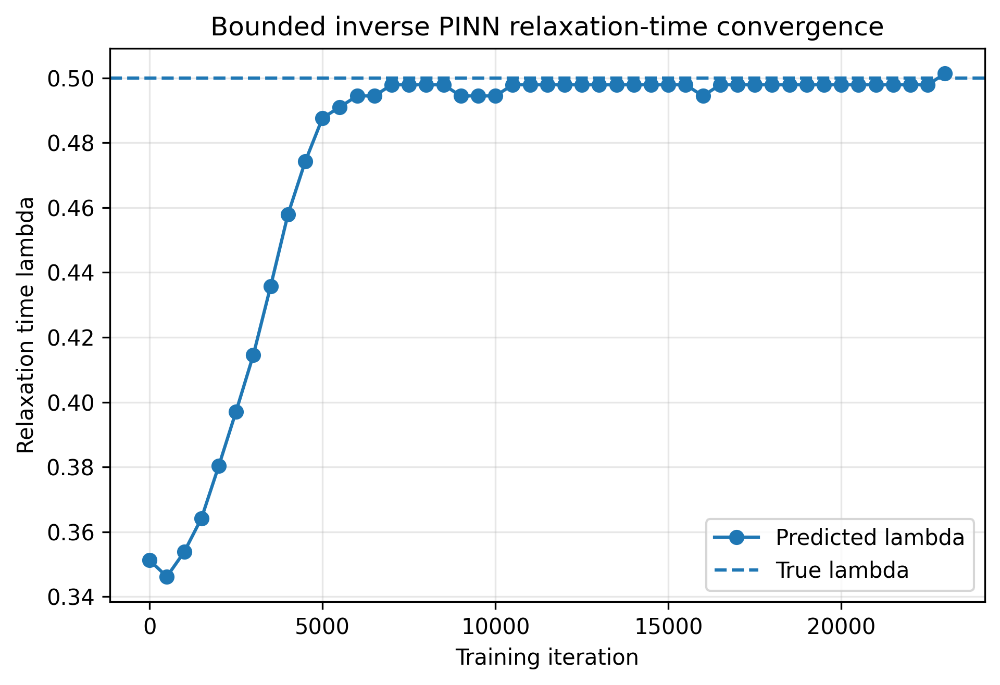

## fig_inverse_pinn_v2_error_sigma.png

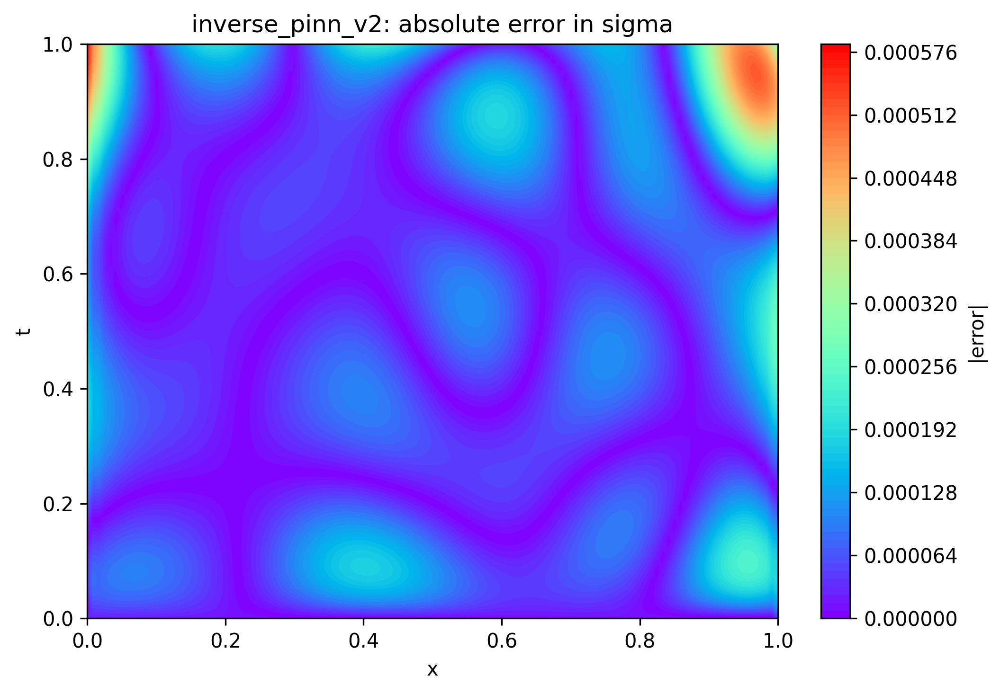

## fig_inverse_pinn_v2_error_u.png

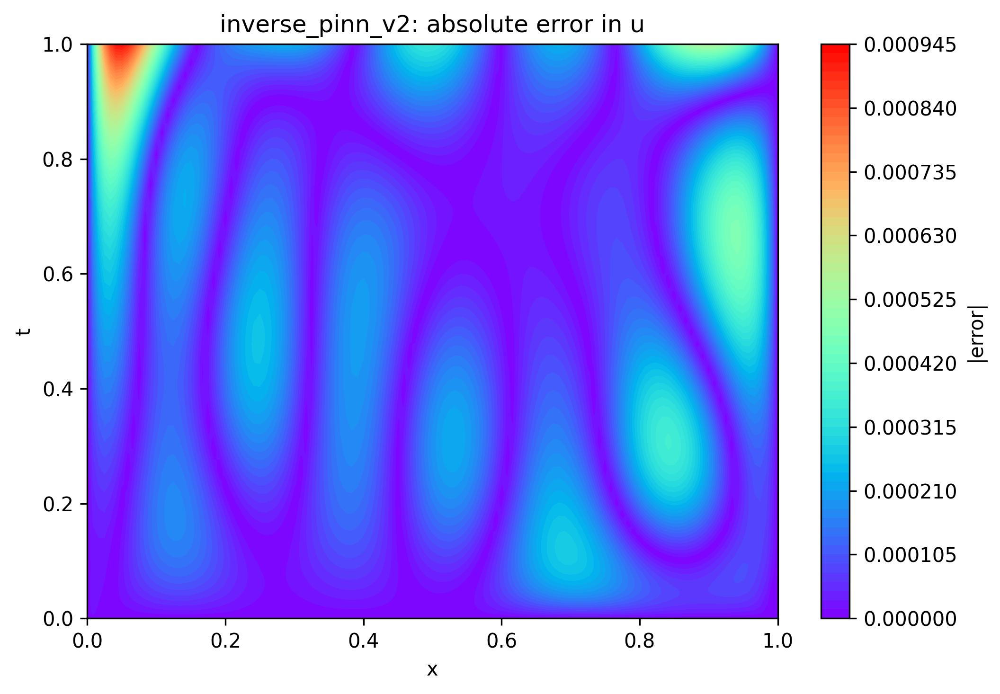

## fig_inverse_pinn_v2_predicted_sigma.png

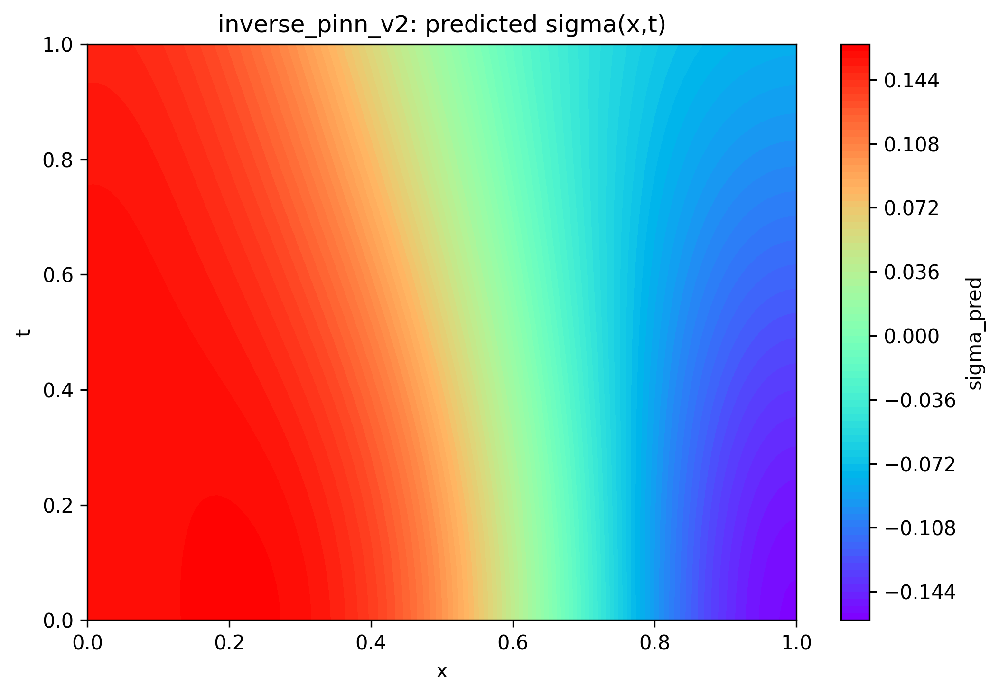

## fig_inverse_pinn_v2_predicted_u.png

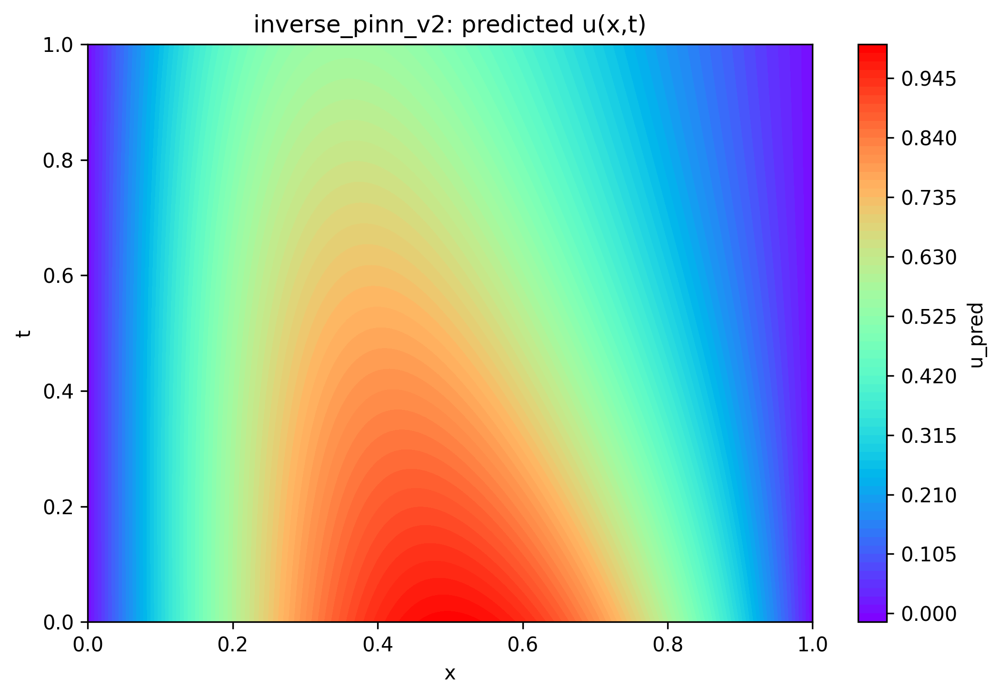

## fig_lambda_sweep_true_vs_predicted_v2.png

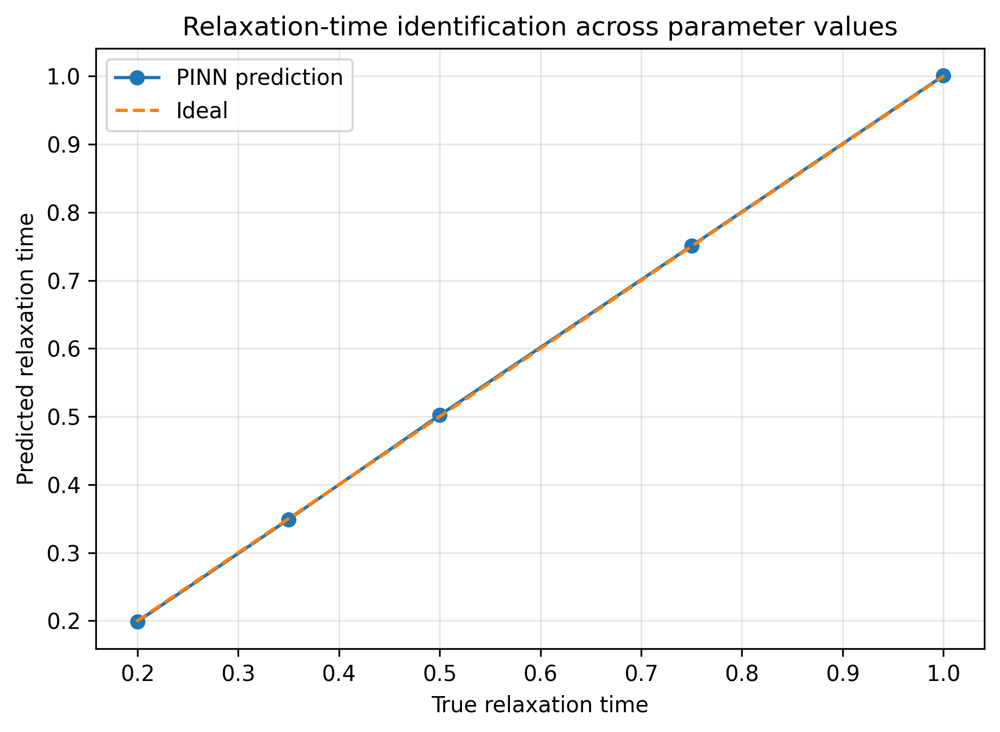

## fig_noise_robustness_lambda_error_v2.png

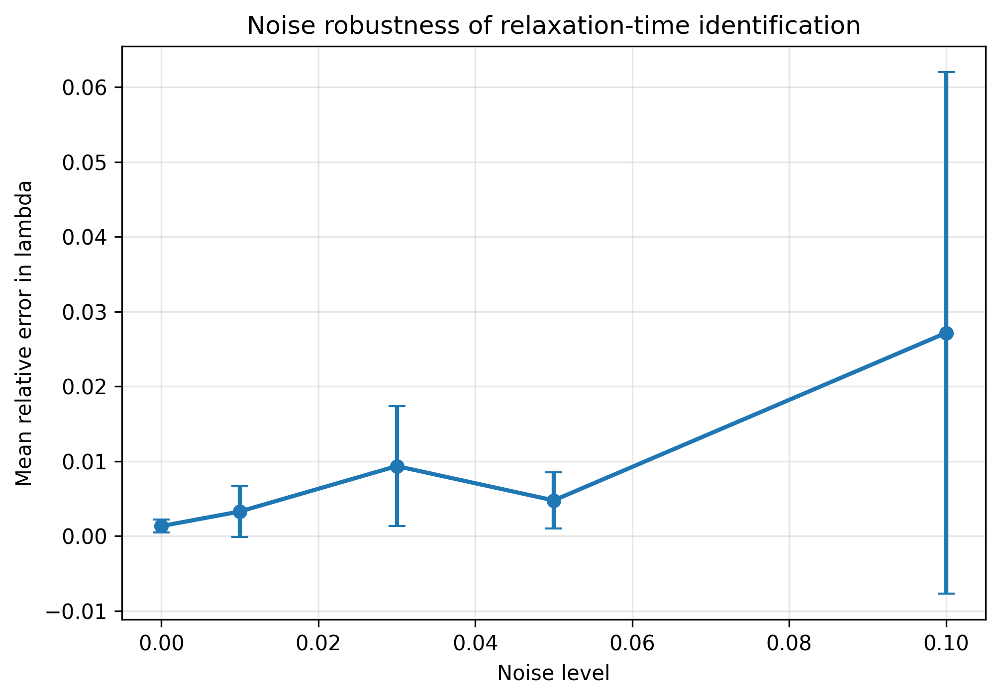

## fig_rar_added_anchor_points_v2.png

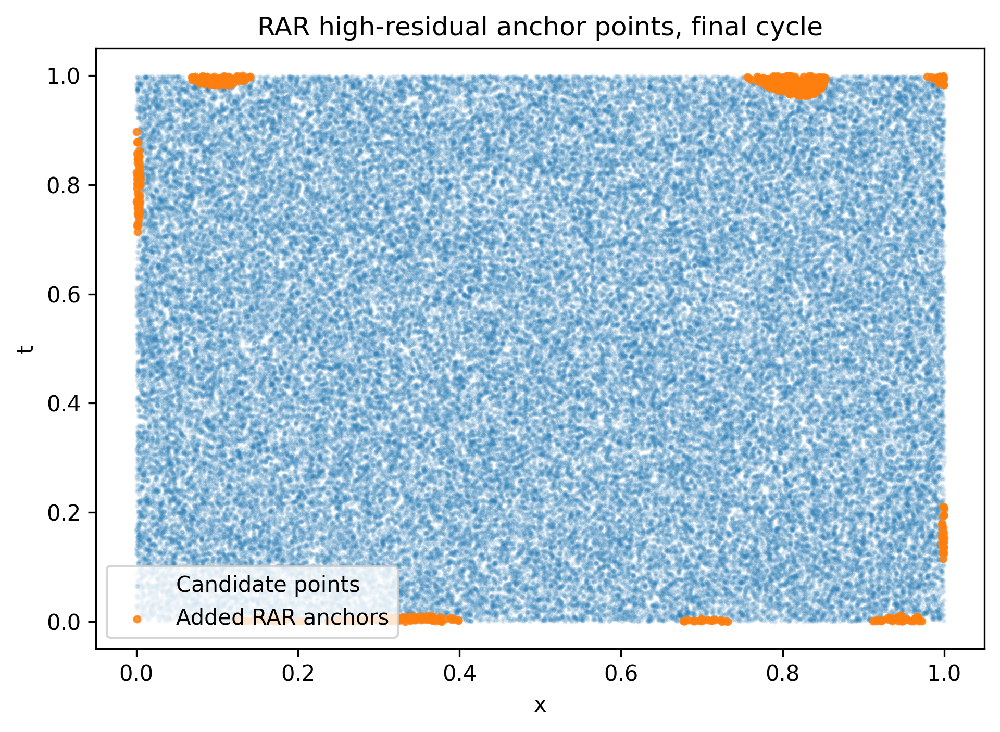

## fig_sparse_data_lambda_error_v2.png

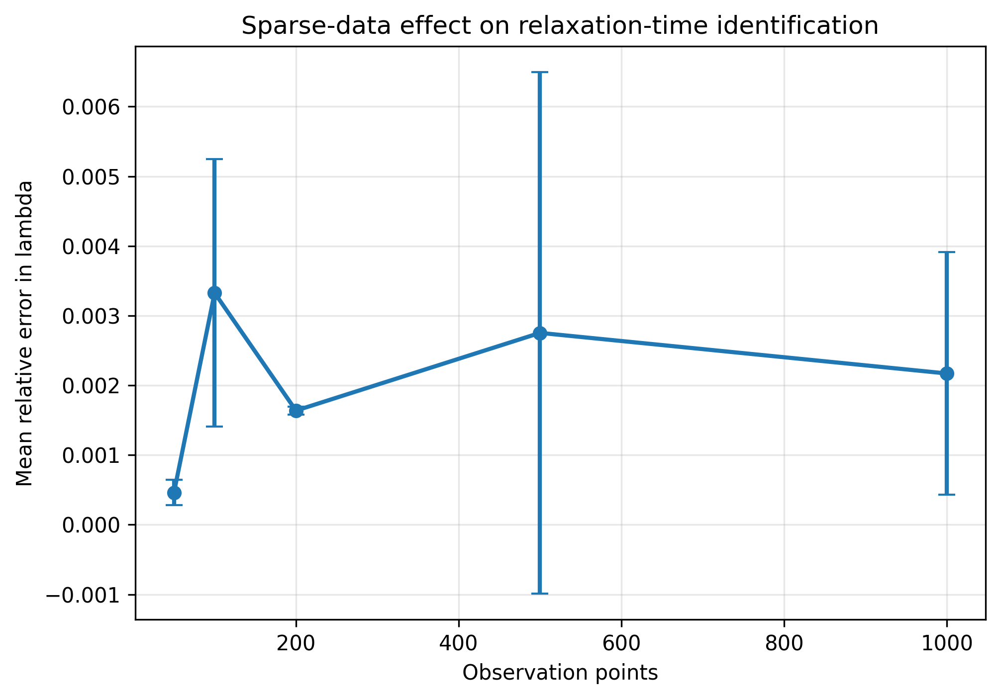

# Output ZIP

/kaggle/working/viscoelastic_pinn_outputs_v3_final.zip

Saved files:
viscoelastic_pinn_outputs_v3_final/figures/fig_01_reference_u.png
viscoelastic_pinn_outputs_v3_final/figures/fig_02_reference_sigma.png
viscoelastic_pinn_outputs_v3_final/figures/fig_adaptive_rar_pinn_v2_error_sigma.png
viscoelastic_pinn_outputs_v3_final/figures/fig_adaptive_rar_pinn_v2_error_u.png
viscoelastic_pinn_outputs_v3_final/figures/fig_adaptive_rar_pinn_v2_predicted_sigma.png
viscoelastic_pinn_outputs_v3_final/figures/fig_adaptive_rar_pinn_v2_predicted_u.png
viscoelastic_pinn_outputs_v3_final/figures/fig_forward_pinn_v2_error_sigma.png
viscoelastic_pinn_outputs_v3_final/figures/fig_forward_pinn_v2_error_u.png
viscoelastic_pinn_outputs_v3_final/figures/fig_forward_pinn_v2_predicted_sigma.png
viscoelastic_pinn_outputs_v3_final/figures/fig_forward_pinn_v2_predicted_u.png
viscoelastic_pinn_outputs_v3_final/figures/fig_inverse_lambda_convergence_v2.png
viscoelastic_pinn_outputs_v3_final/figures/fig_inverse_pinn_v2

In [19]:
zip_base = "viscoelastic_pinn_outputs_v3_final"
zip_file = shutil.make_archive(zip_base, "zip", OUTDIR)
print("Created ZIP:", zip_file)

def display_all_saved_tables_and_figures(max_rows=MAX_TABLE_ROWS_TO_DISPLAY):
    """Display every saved table and figure in the Kaggle output area."""
    table_files = sorted(TABLEDIR.glob("*.csv"))
    figure_files = sorted(FIGDIR.glob("*.png"))

    display(Markdown("# All Saved Tables"))
    if not table_files:
        print("No tables found.")
    for table_path in table_files:
        display(Markdown(f"## {table_path.name}"))
        df = pd.read_csv(table_path)
        if len(df) > max_rows:
            display(df.head(max_rows))
            print(f"Displayed first {max_rows} of {len(df)} rows.")
        else:
            display(df)

    display(Markdown("# All Saved Figures"))
    if not figure_files:
        print("No figures found.")
    for fig_path in figure_files:
        display(Markdown(f"## {fig_path.name}"))
        display(Image(filename=str(fig_path)))

    display(Markdown("# Output ZIP"))
    print(zip_file)

if DISPLAY_ALL_OUTPUTS_AT_END:
    display_all_saved_tables_and_figures()

print("\nSaved files:")
for path in sorted(OUTDIR.rglob("*")):
    if path.is_file():
        print(path)

# Recommended Article Language

Use this after running the notebook:

> The proposed adaptive hard-constrained DeepXDE-PINN solves a nonlinear viscoelastic governing system and identifies the relaxation time from sparse interior measurements. Hard output constraints enforce the boundary and initial conditions exactly, while the bounded trainable parameterization keeps the relaxation time physically admissible. Residual-based adaptive refinement further reduces prediction error by adding collocation points in high-residual regions.

Avoid saying FEM/FDM cannot solve the problem. Say PINNs provide a mesh-free and inverse-capable alternative.